# Tirando sinais digitais - $x[n]$ ... pra fora do computador - $x(t)$!

Neste Notebook iremos trabalhar em como:
1. Criar um sinal `osc`, com frequência e duração controladas.
2. Sintetizar um sinal ***periódico e aleatório***, com frequência e duração controladas.
3. Plotar sinais em amostras, $x[n]$, tempo, $x(t)$, e frequência, $\mathcal{X}(\omega)$.

In [9]:
import numpy as np
import matplotlib.pyplot as plt

In [10]:
import sys

In [11]:
try:
    from google.colab import drive

    drive.mount('/content/drive')
    sys.path.append('/content/drive/MyDrive/UFG/01_teaching/')

except:
    sys.path.append('/home/kuntur/Documents') # laptop version
    # sys.path.append('/media/sdcard/Documents/') # tablet version

Mounted at /content/drive


In [16]:
from lib.myAudioProcessingLib import *
from lib.le03_basic_signal_library_luccas import *
#from lib.myPlotLib import *

Complete a função `create_sine_signal`, que permite criar um **sinal oscilatório** (*le03, p. 24*):

$$
\Large
x[n] = \, ...
$$

controlado pela sua:

- ***frequência*** $(f)$ [Hz] (*le04, p. 11*):

$$
\Large
f = \, ...
$$

- e ***duração*** $(d)$ [s] :

$$
\Large
d = N \, T_{s}
$$

In [17]:
def create_sine_signal(f=150.0, dur=1.0, fs=48e3):
    '''
    f  : Signal frequency (Hz)
    dur: Duration (s)
    fs : Sampling frequency
    '''
    t = np.arange(int(dur * fs)) / fs   # instantes de tempo em segundos
    x = np.sin(2 * np.pi * f * t)

    return x, fs

teste sua função, para um sinal de 220 Hz e 1.5 segundos de duração:

In [18]:
f   = 150
dur = 1.5

x1, fs1 = create_sine_signal(f, dur)

In [19]:
play(x1, fs1)

Qual é a ***frequencia audível*** do sinal?

In [ ]:
# consigo ouvir a partir de 150Hz

Qual é o período $(P_{1})$, tamanho $(N_{1})$, e frequência de amostragem $(f_{s_{1}})$ do sinal?

In [26]:
P1 = fs1/f
N1 = len(x1)
print(P1, N1, fs1)

320.0 72000 48000.0


['/content/lib/le03_basic_signal_library_luccas.py']


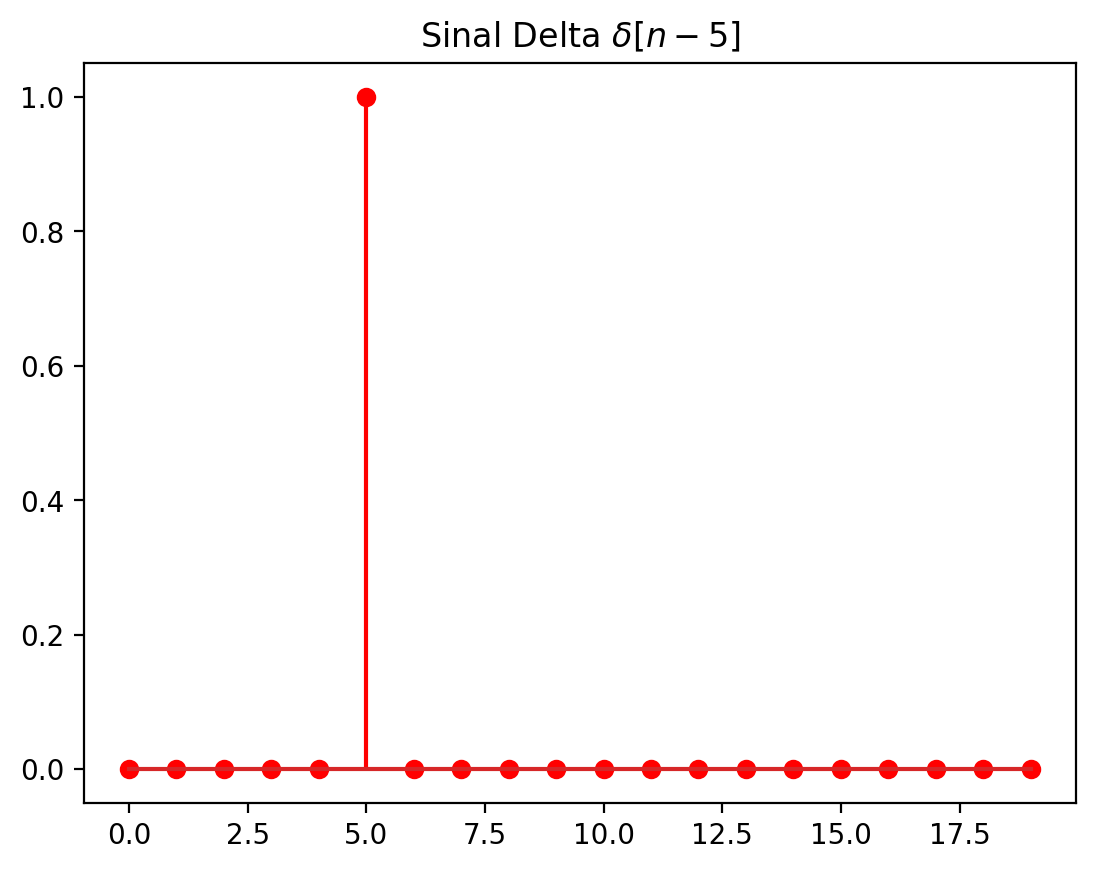

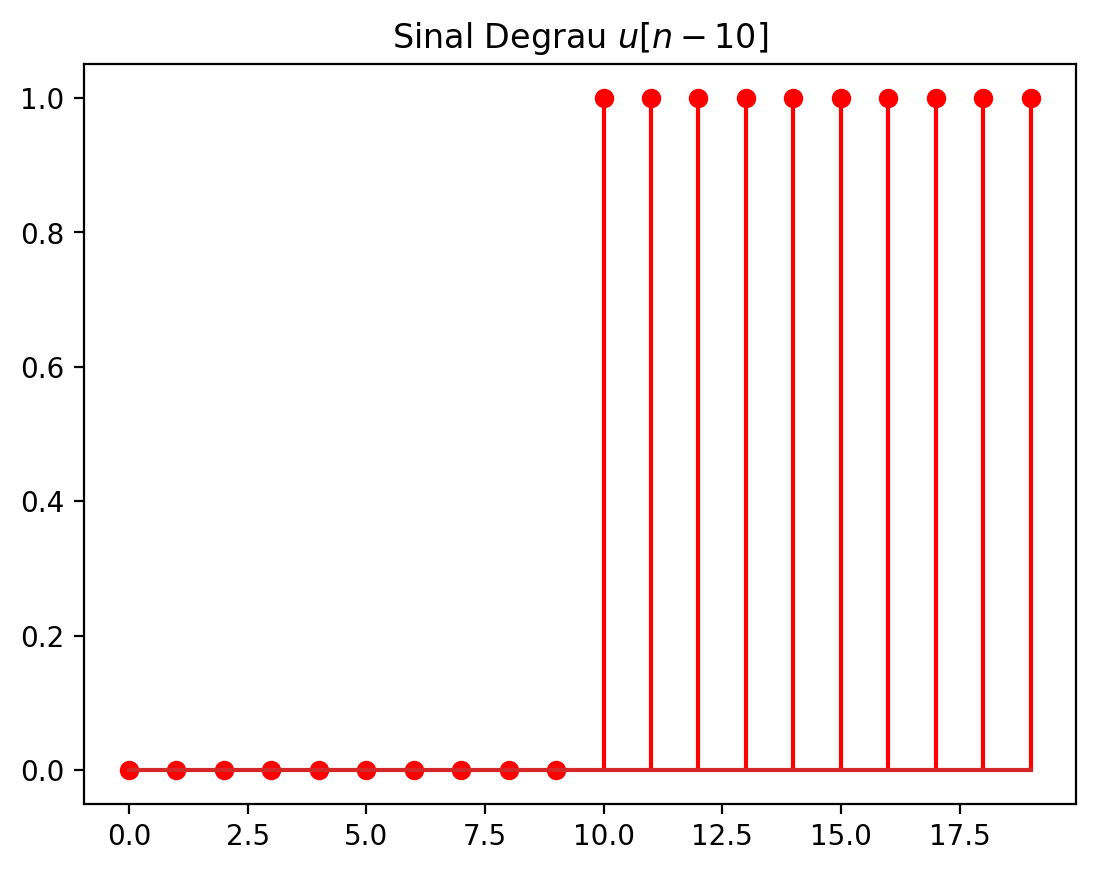

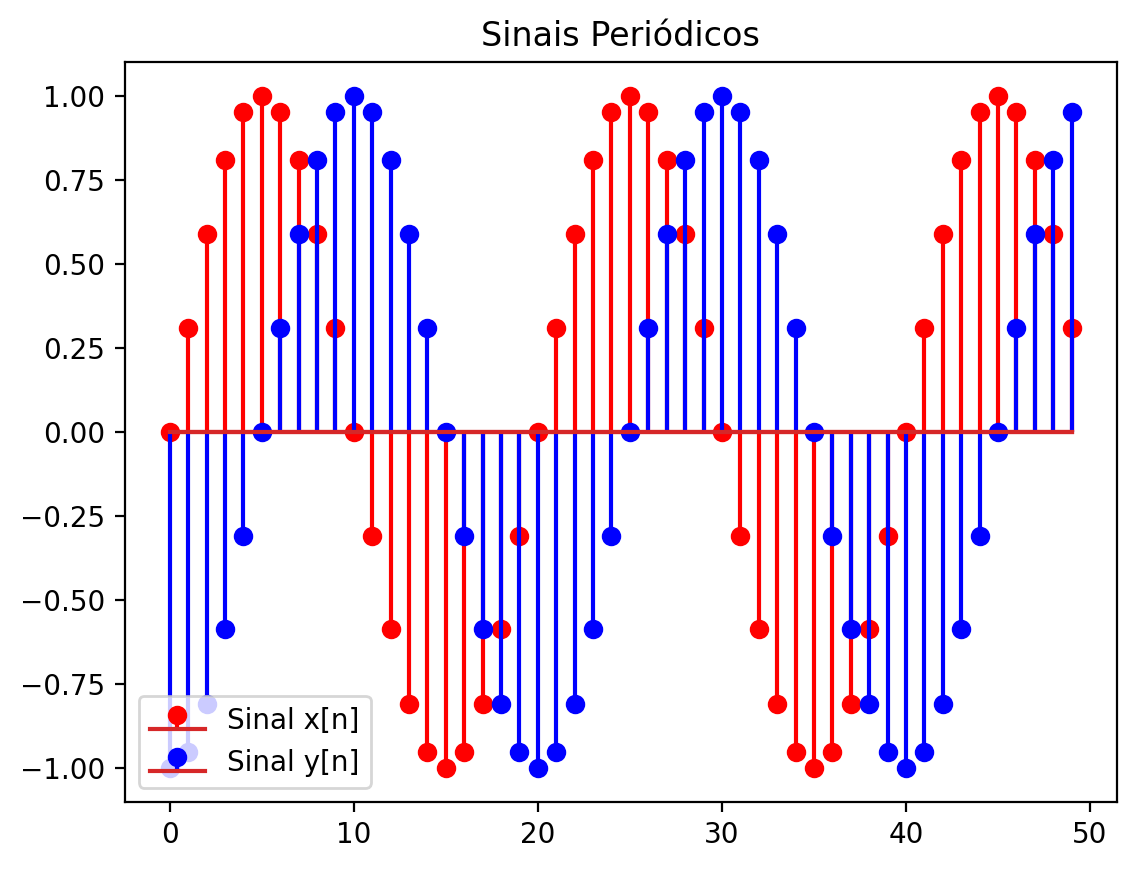

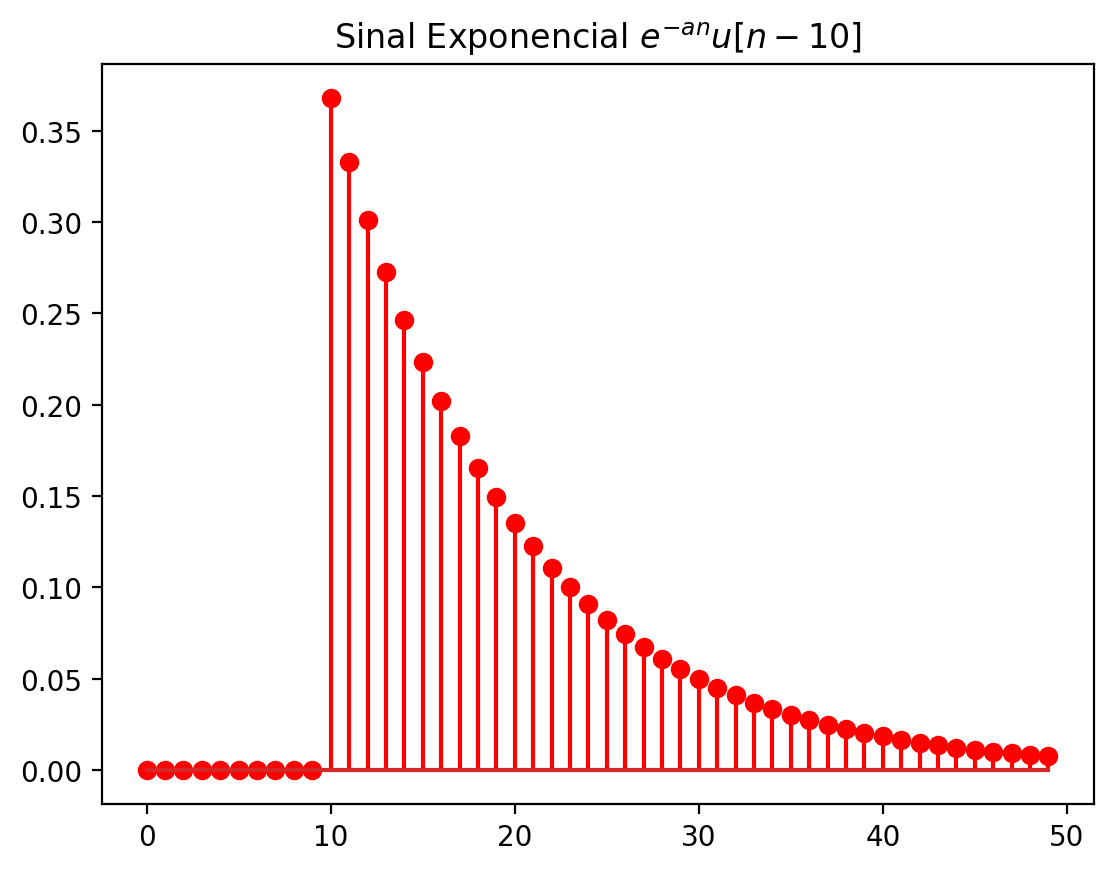

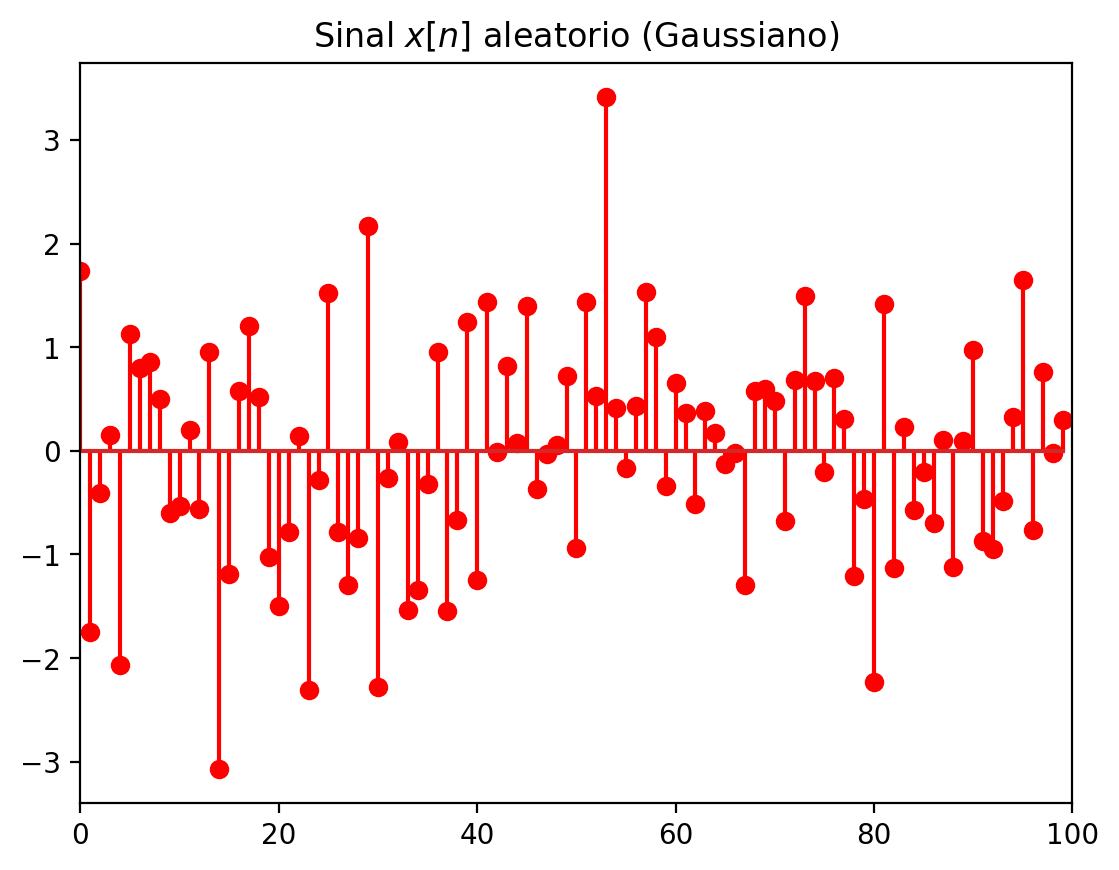

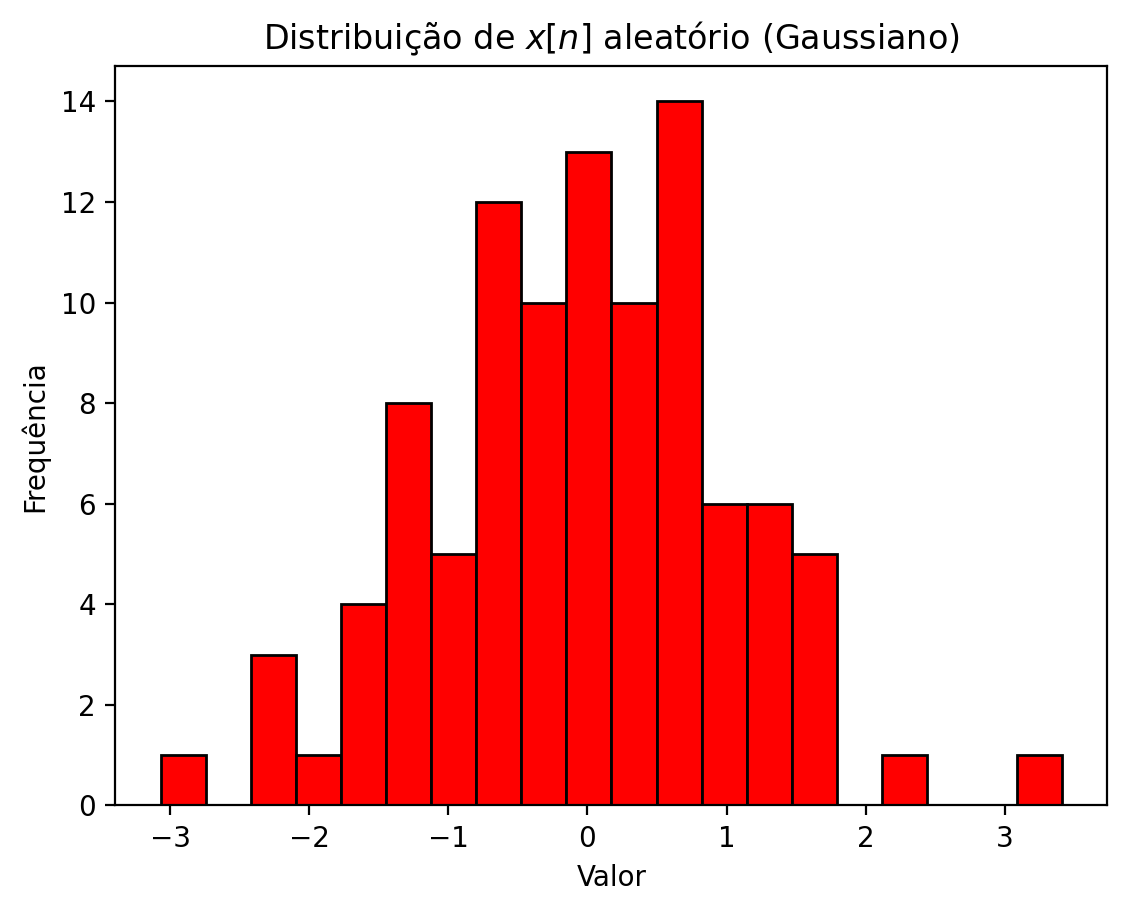

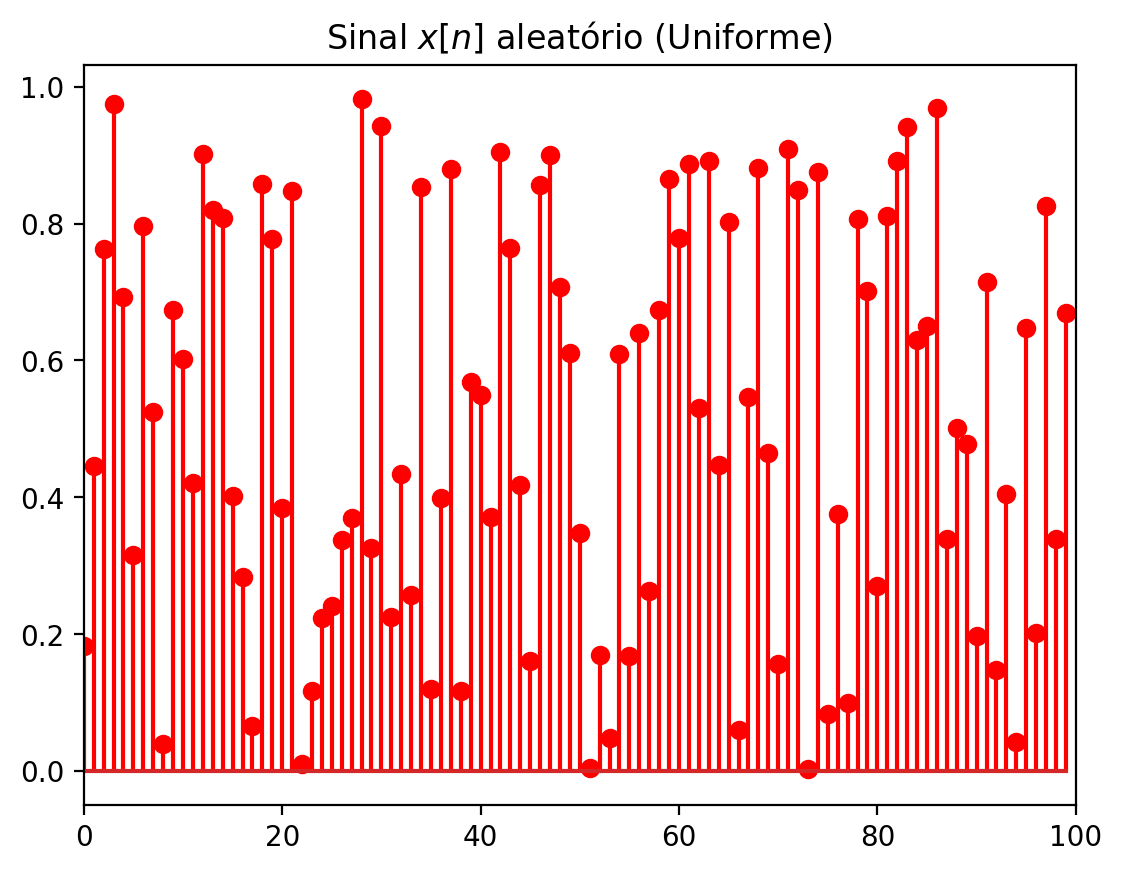

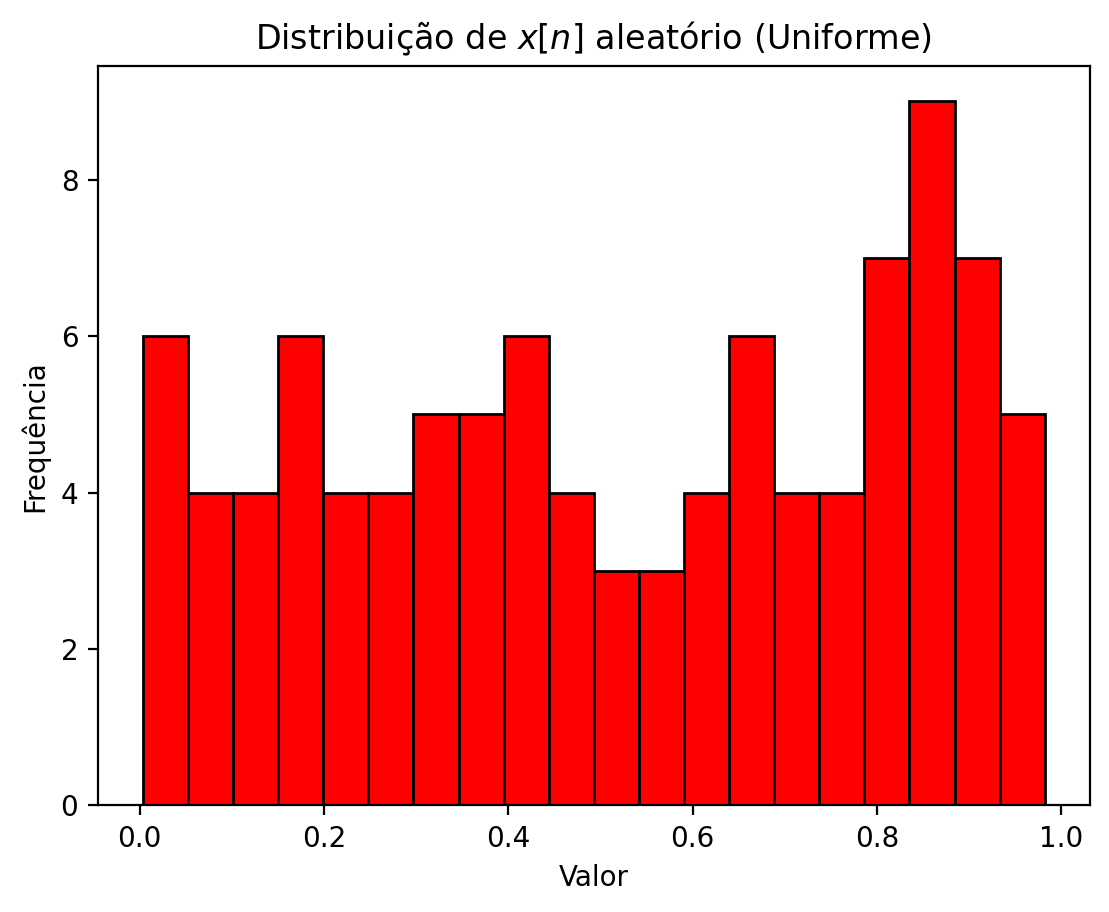

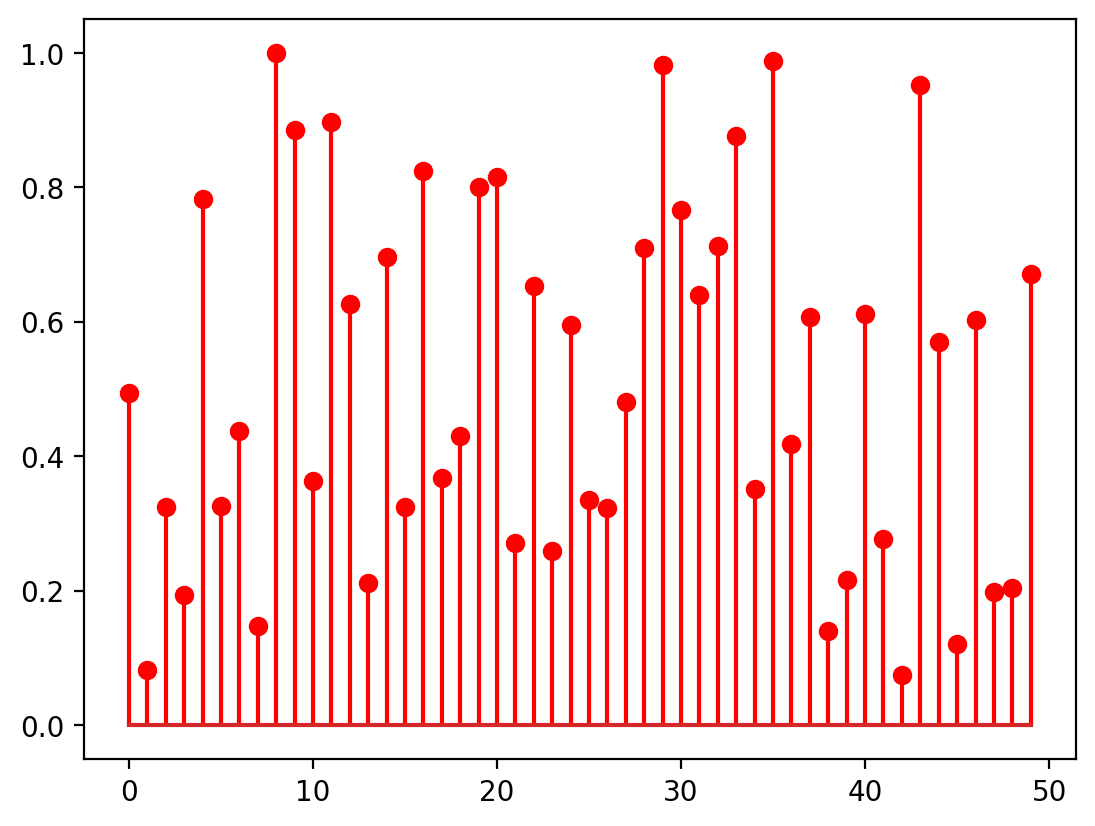

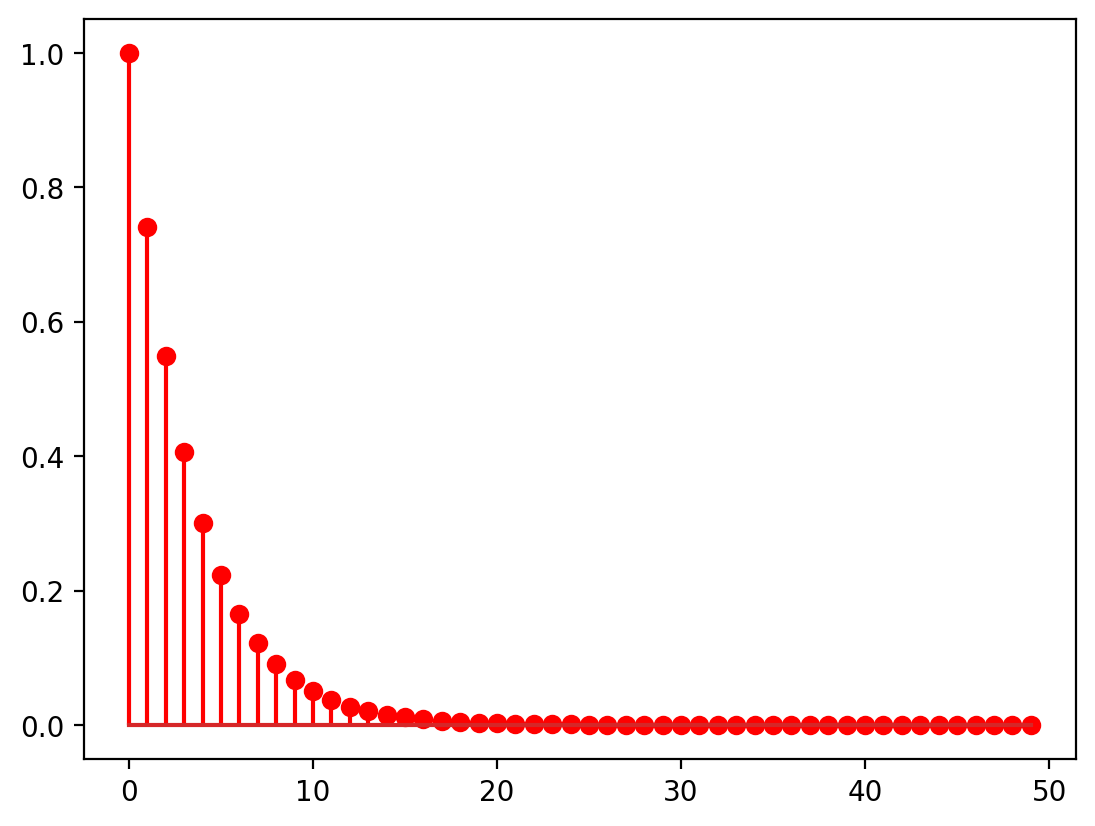

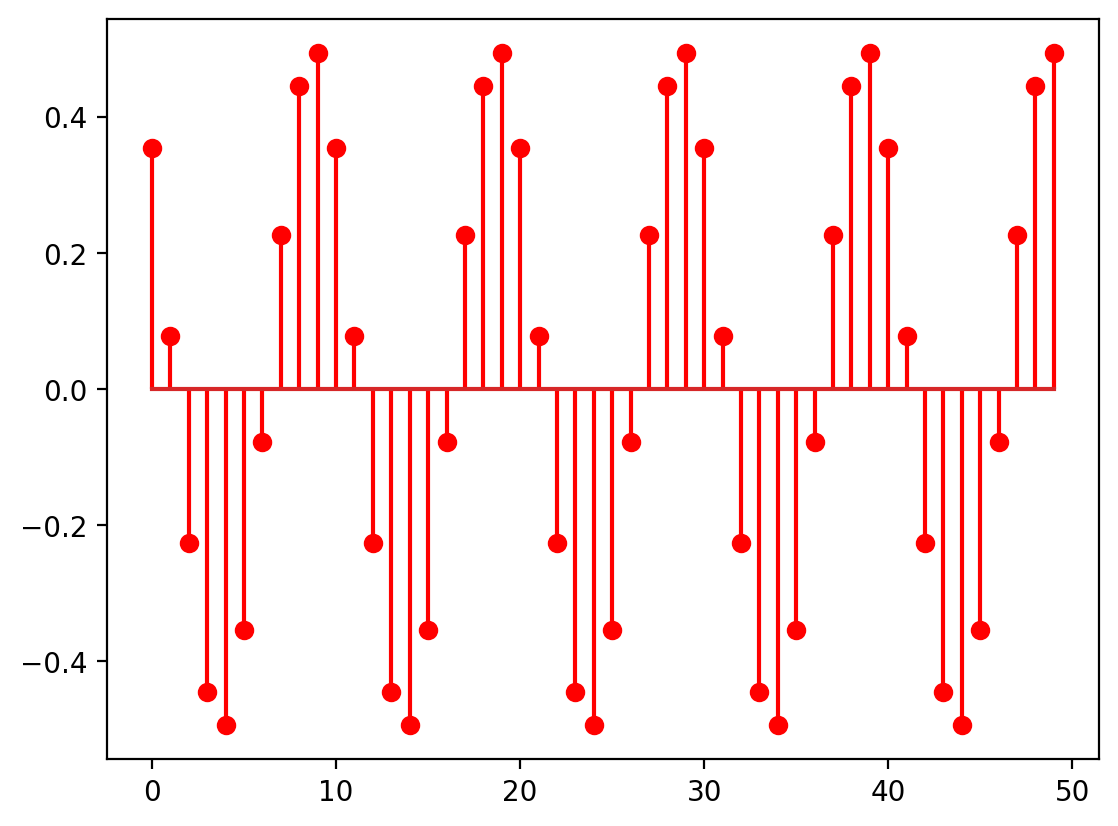

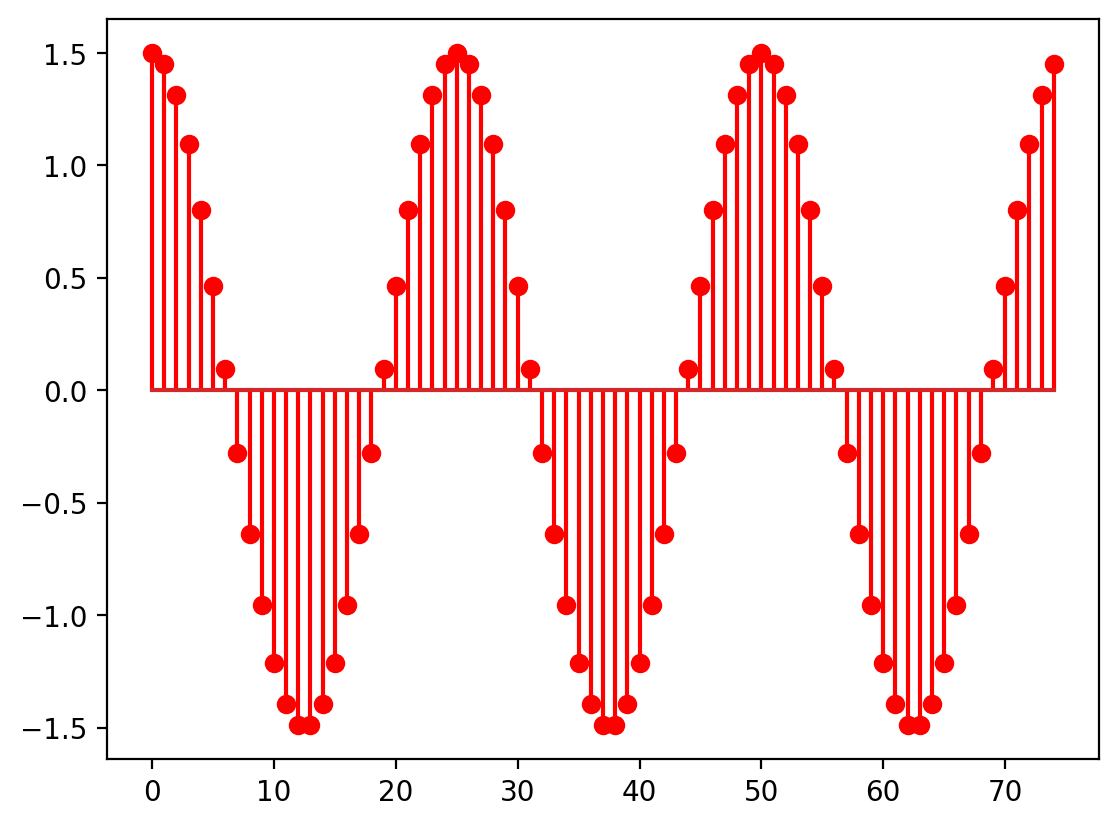

In [28]:
import glob, importlib.util

arquivos = glob.glob("/content/lib/le03*.py")
print(arquivos)

spec = importlib.util.spec_from_file_location("signal_lib", arquivos[0])
signal_lib = importlib.util.module_from_spec(spec)
spec.loader.exec_module(signal_lib)

SIGNALgenerate = signal_lib.SIGNALgenerate

In [23]:
import inspect
print(inspect.signature(SIGNALgenerate))
print(inspect.getsource(SIGNALgenerate))

(N=100, signal='delta', params=None)
def SIGNALgenerate(N=100, signal='delta', params=None):
    n = np.arange(N)
    x = np.zeros(N)

    def get_val(key, default):
        if isinstance(params, dict):
            return params.get(key, default)
        return params if params is not None else default

    if signal == 'delta':
        k = int(get_val('k', 0))
        if 0 <= k < N: x[k] = 1

    elif signal == 'step':
        k = int(get_val('k', 0))
        x[k:] = 1

    elif signal == 'exp':
        a_val = float(get_val('a', 0.1))
        b_val = float(get_val('b', 1.0))
        x = b_val * np.exp(-a_val * n)

    elif signal == 'osc':
        # Adicionando Amplitude (A) e Fase (phi) para melhor visualização
        P = float(get_val('P', 20))
        A = float(get_val('A', 1.0))
        phi = float(get_val('phi', 0.0))
        wo = 2 * np.pi / P
        # Usar cos ajuda a ver o período começando do pico se phi=0
        x = A * np.cos(wo * n + phi)

    elif signal == 'random':


Se mudar a frequencia de amostragem, o que acontece?

In [ ]:
# O período muda, já que é relacionado à frequencia de amostragem.

Agora vamos recriar a mesma função a partir da nossa conhecida primitiva `osc`:

In [29]:
import numpy as np

fs2 = 44.1e3

P2 = fs2 / f
N2 = int(dur * fs2)

x2 = SIGNALgenerate(N2, 'osc', {'P': P2})
n2 = np.arange(N2)

In [25]:
play(x2, fs2)

Compare o período $(P_{2})$, tamanho $(N_{2})$, e frequência de amostragem $(f_{s_{2}})$ deste novo sinal com o anterior:

In [30]:
print(P2, N2, fs2)

print(P1, N1, fs1)

294.0 66150 44100.0
320.0 72000 48000.0


In [ ]:
# # P2 e N2 são menores que P1 e N1 porque fs2 < fs1: com menos amostras por segundo, cada ciclo e o sinal inteiro têm menos amostras, mas a frequência e a duração continuam as mesmas.

Para verificar o resultado, plote os dois sinais resultantes no "***domínio do tempo***", ou seja, mostrando o **eixo horizontal** em unidade de **segundos**:

$$
\Large
t = n \, T_{s}
$$

***Dica:*** Use `SIGNALplot` para plotar o sinal. \
Se precisar, faça um recorte para melhorar a visualização dos sinais.

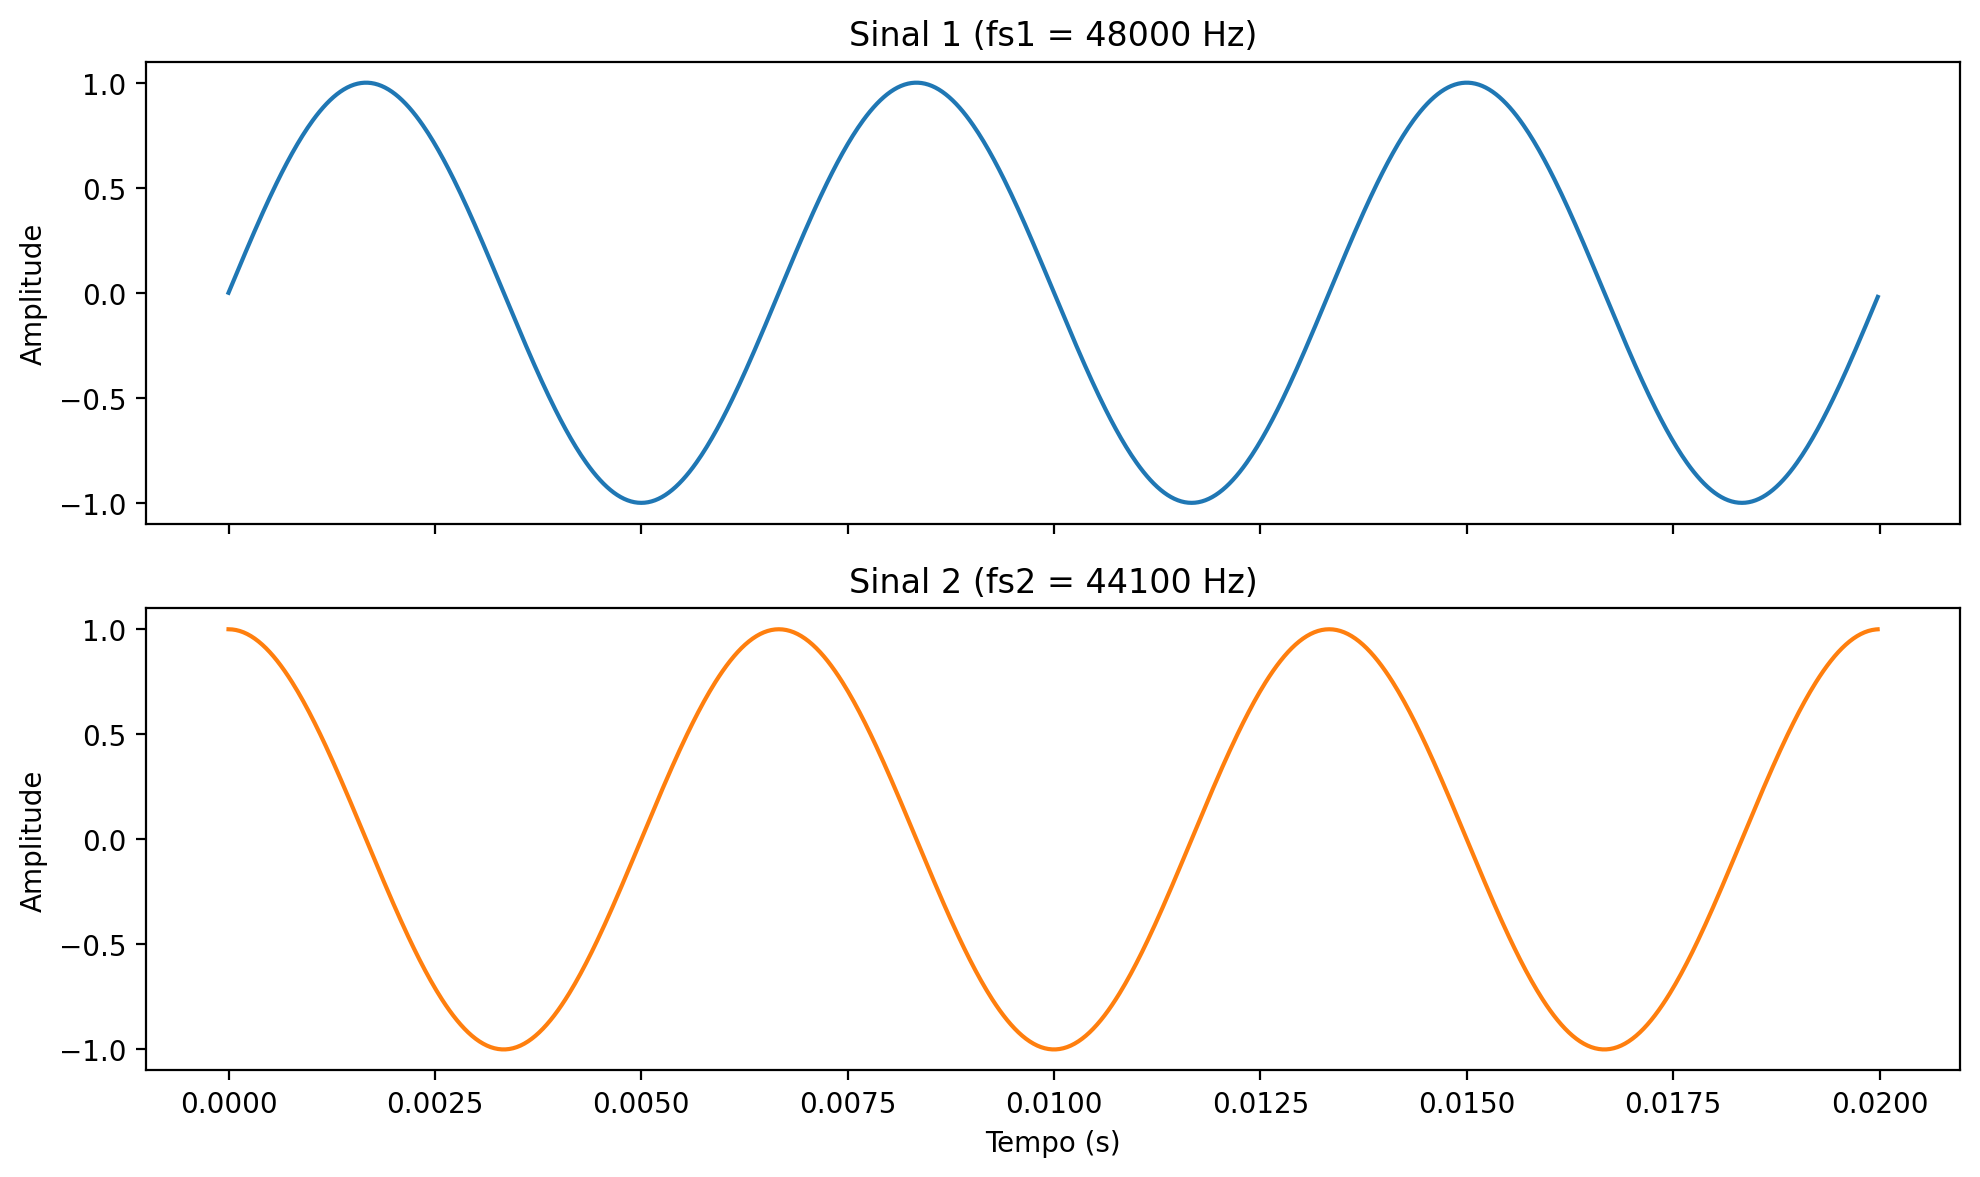

In [31]:
import numpy as np
import matplotlib.pyplot as plt

# Vetor de tempo: t = n * Ts = n / fs
t1 = np.arange(len(x1)) / fs1
t2 = np.arange(len(x2)) / fs2

# Plot (recorte dos primeiros 20 ms para ver as ondas)
m1 = t1 < 0.02
m2 = t2 < 0.02

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

ax[0].plot(t1[m1], x1[m1])
ax[0].set_title(f'Sinal 1 (fs1 = {fs1:.0f} Hz)')
ax[0].set_ylabel('Amplitude')

ax[1].plot(t2[m2], x2[m2], color='tab:orange')
ax[1].set_title(f'Sinal 2 (fs2 = {fs2:.0f} Hz)')
ax[1].set_xlabel('Tempo (s)')
ax[1].set_ylabel('Amplitude')

plt.tight_layout()
plt.show()

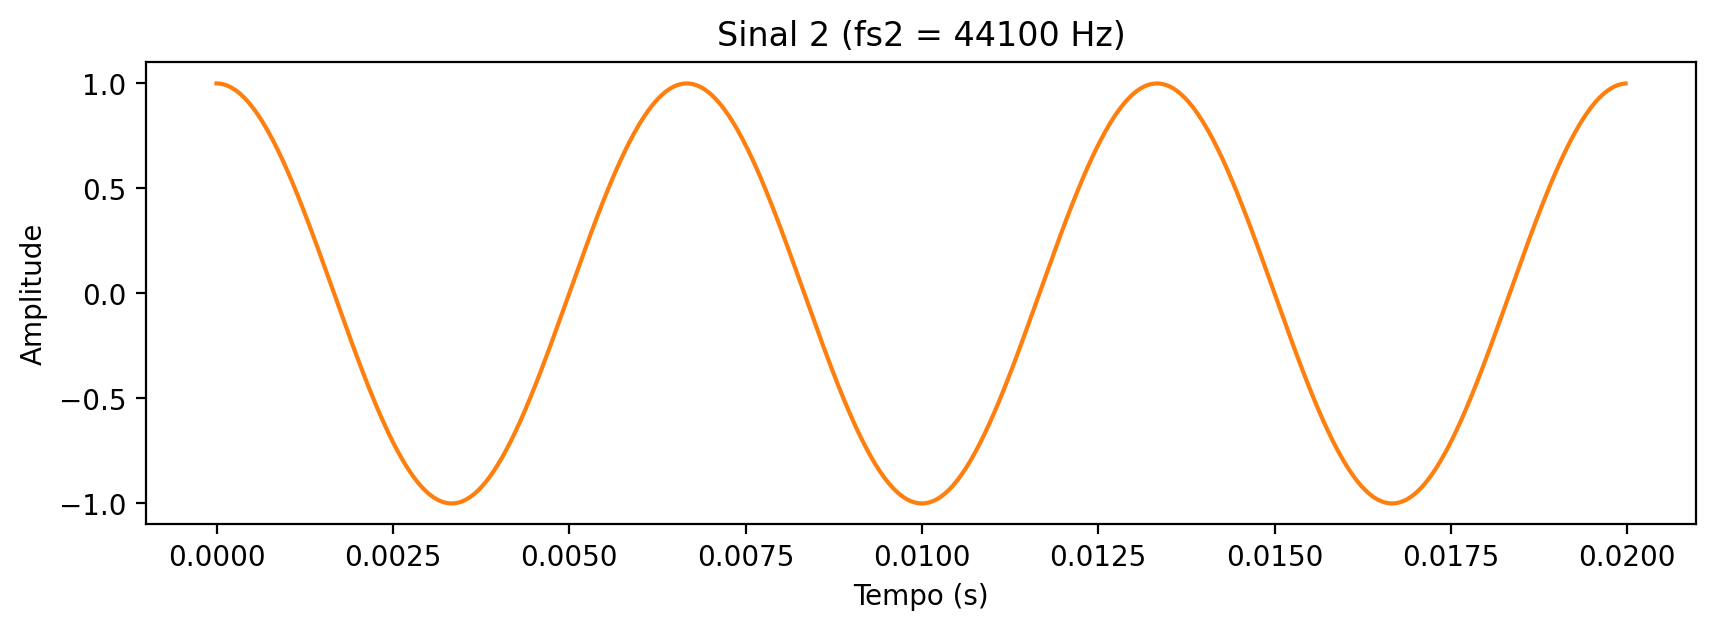

In [32]:
import numpy as np
import matplotlib.pyplot as plt

# Vetor de tempo: t = n * Ts = n / fs
t2 = np.arange(len(x2)) / fs2

# Plot (recorte dos primeiros 20 ms para ver as ondas)
m2 = t2 < 0.02

plt.figure(figsize=(10, 3))
plt.plot(t2[m2], x2[m2], color='tab:orange')
plt.title(f'Sinal 2 (fs2 = {fs2:.0f} Hz)')
plt.xlabel('Tempo (s)')
plt.ylabel('Amplitude')
plt.show()

<img src="./figures/sine_01.png" alt="" width="600"/>

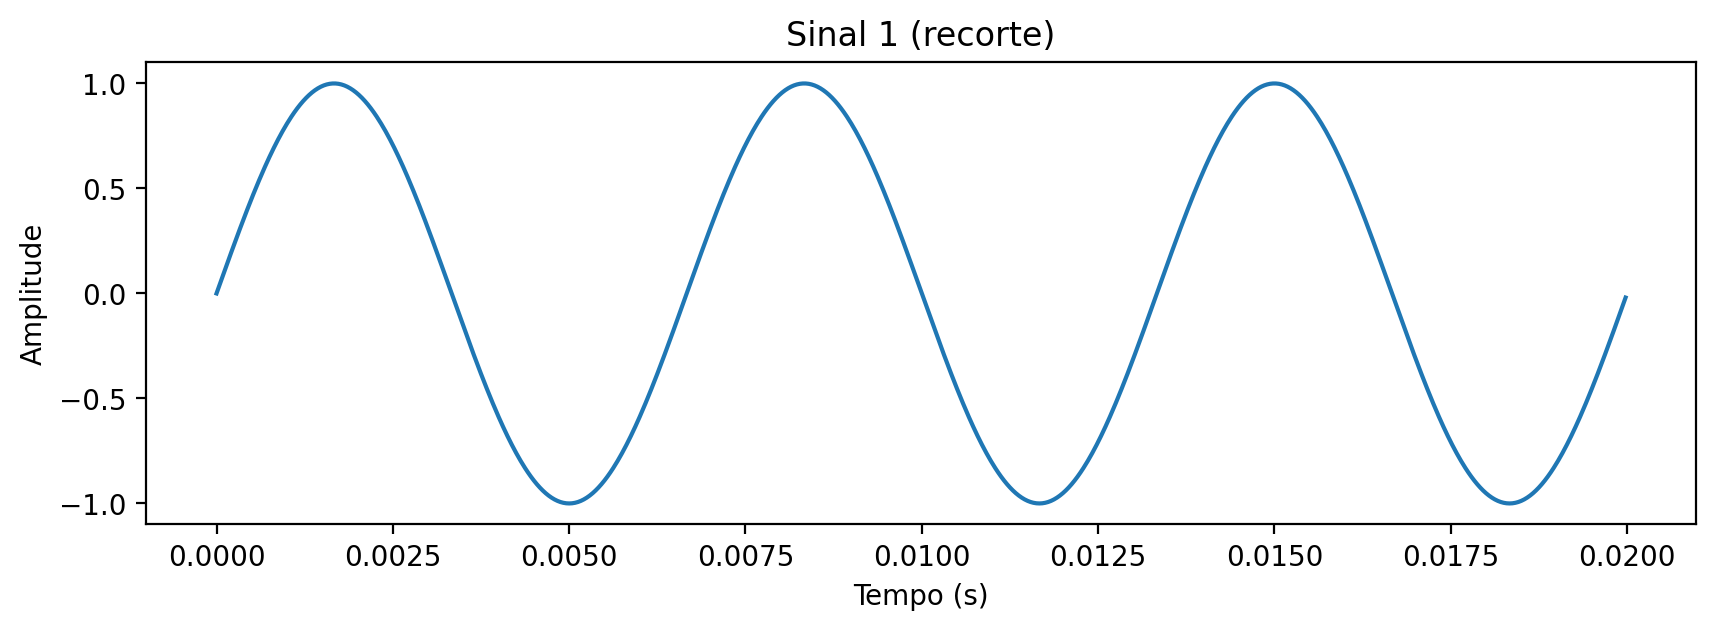

In [33]:
import numpy as np
import matplotlib.pyplot as plt

# Recorte: 3 períodos do sinal (3 * 320 = 960 amostras, ou 20 ms)
r = int(3 * P1)

# Plot
plt.figure(figsize=(10, 3))
plt.plot(t1[:r], x1[:r])
plt.title('Sinal 1 (recorte)')
plt.xlabel('Tempo (s)')
plt.ylabel('Amplitude')
plt.show()

<img src="./figures/sine_02.png" alt="" width="600"/>

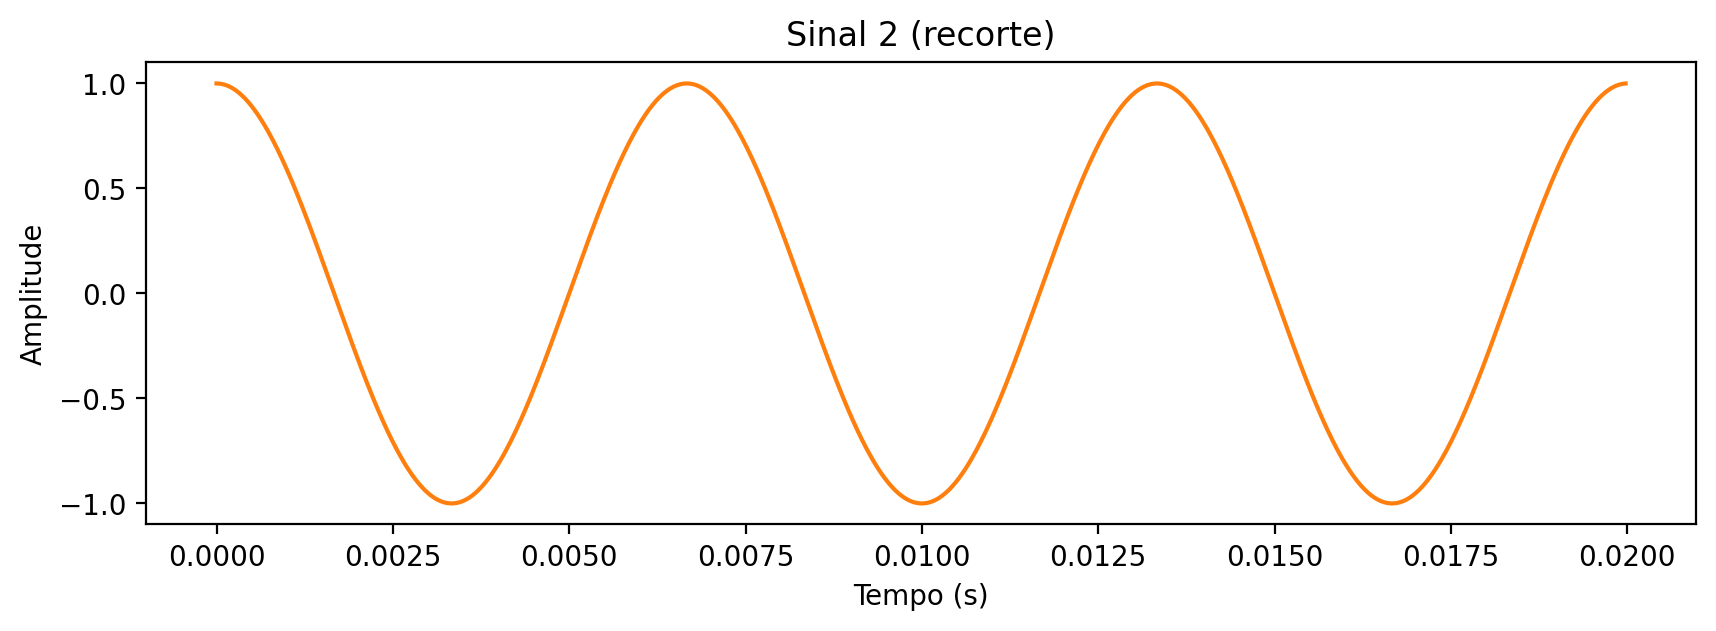

In [34]:
import numpy as np
import matplotlib.pyplot as plt

# Recorte: 3 períodos do sinal (3 * 294 = 882 amostras, ou 20 ms)
r = int(3 * P2)

# Plot
plt.figure(figsize=(10, 3))
plt.plot(t2[:r], x2[:r], color='tab:orange')
plt.title('Sinal 2 (recorte)')
plt.xlabel('Tempo (s)')
plt.ylabel('Amplitude')
plt.show()

Faça um novo recorte para plotar ***apenas*** 2.5 períodos de cada sinal.

***Dica:*** Verifique o resultado mostrando o **eixo horizontal** no "***domínio das amostras***".

<img src="./figures/sine_03.png" alt="" width="600"/>

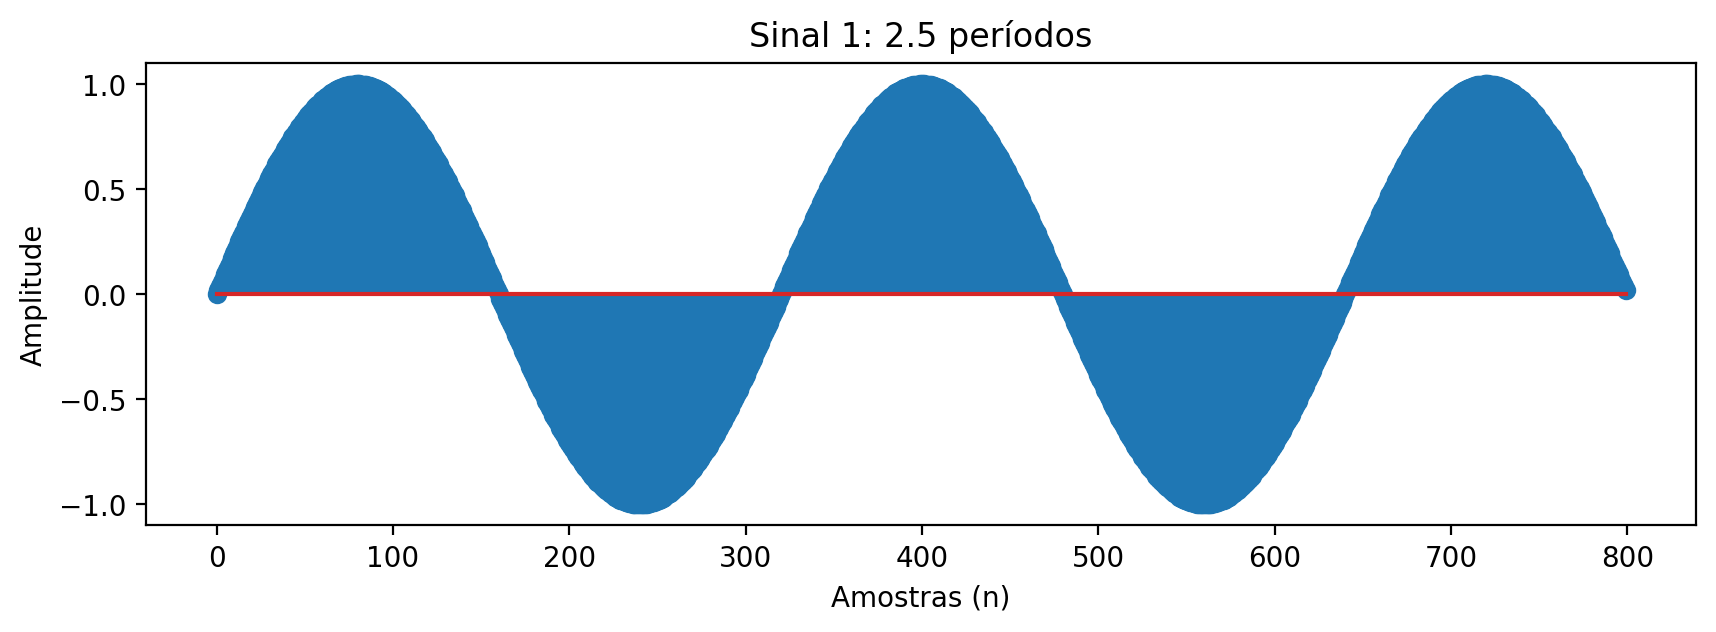

In [35]:
import numpy as np
import matplotlib.pyplot as plt

# Recorte: 2.5 períodos (2.5 * 320 = 800 amostras)
r = int(2.5 * P1)

# Eixo em amostras
n1 = np.arange(len(x1))

# Plot
plt.figure(figsize=(10, 3))
plt.stem(n1[:r], x1[:r])
plt.title('Sinal 1: 2.5 períodos')
plt.xlabel('Amostras (n)')
plt.ylabel('Amplitude')
plt.show()

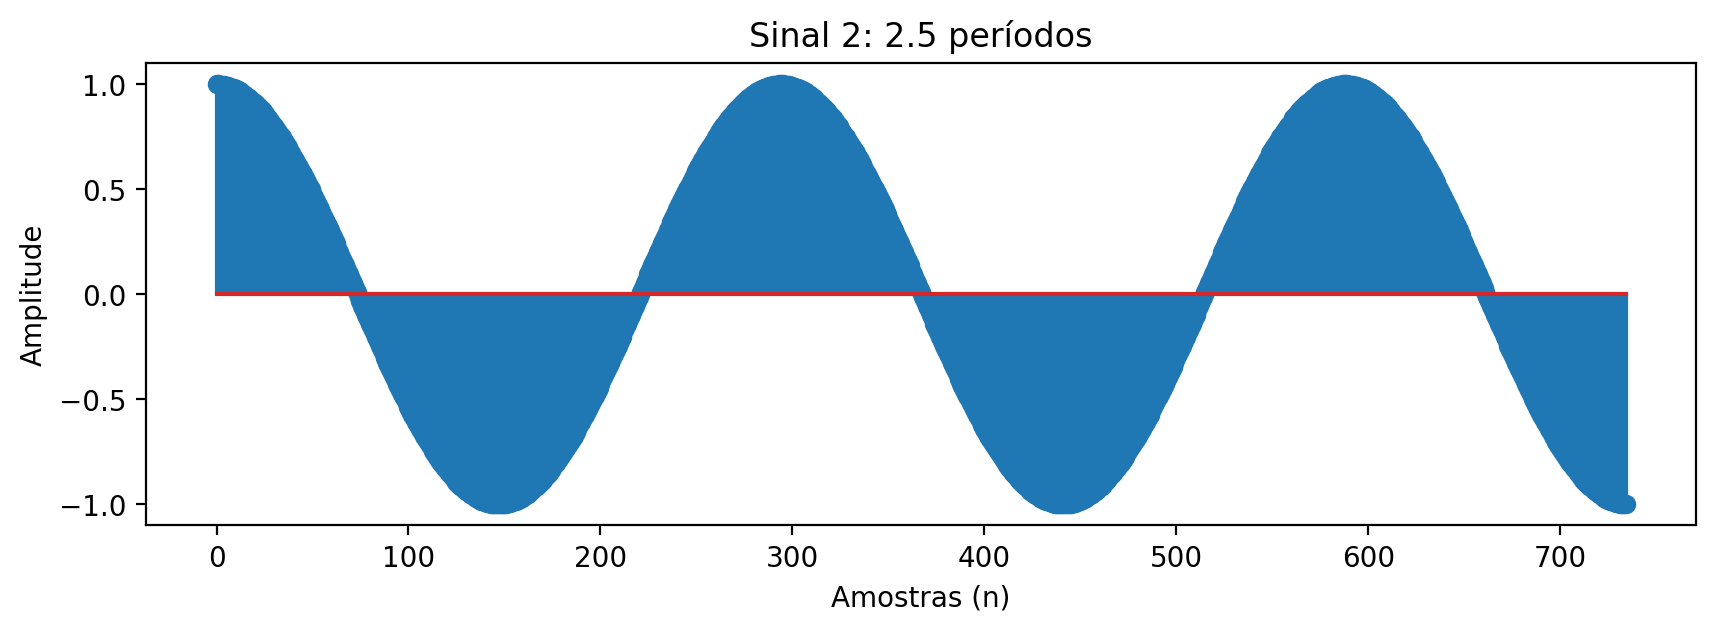

In [36]:
import numpy as np
import matplotlib.pyplot as plt

# Recorte: 2.5 períodos (2.5 * 294 = 735 amostras)
r = int(2.5 * P2)

# Eixo em amostras
n2 = np.arange(len(x2))

# Plot
plt.figure(figsize=(10, 3))
plt.stem(n2[:r], x2[:r])
plt.title('Sinal 2: 2.5 períodos')
plt.xlabel('Amostras (n)')
plt.ylabel('Amplitude')
plt.show()

## Desafio

A partir da primitiva `SIGNALgenerate`, aumente a sua **biblioteca de processamento sinais** com a função `SIGNALtone`, que permita criar um ***tom*** controlado por ***frequencia*** e ***duração***.

In [37]:
import numpy as np

def SIGNALtone(f=440.0, dur=1.0):
    '''
    Tone with predefined frequency and duration

    f  : Signal frequency (Hz)
    dur: Duration (s)

    x  : Output signal
    fs : Sampling freq. (CD standard by def.)
    '''

    fs = 44.1e3  # Sampling freq. (CD standard)

    N = int(dur * fs)   # número de amostras
    P = fs / f          # período em amostras

    x = SIGNALgenerate(N, 'osc', {'P': P})

    return x, fs

Teste a função para um sinal de 330 Hz com 3 segundos de duração.

In [38]:
f = 330.0 # signal freq (Hz)
dur = 3.0 # duration (s)

In [39]:
x, fs = SIGNALtone(f, dur)

In [40]:
play(x, fs)

## Revelando a "*velocidade*" dos sinais

Como comprovar que estamos gerando as frequências corretas?

***Dica:*** Estude a função `np.fft.fft` que permite evidenciar as "*velocidades*" de sinais. \
Use `SIGNALplot` para plotar a **magnitude** da FFT no domínio das amostras.

<img src="./figures/spec_01.png" alt="" width="600"/>

In [ ]:
# help(np.fft.fft)

In [ ]:
# Resposta
# A FFT decompõe o sinal em frequências: um tom puro aparece como um pico no gráfico da magnitude. Se o pico estiver onde esperado, a frequência vai estarcorreta.

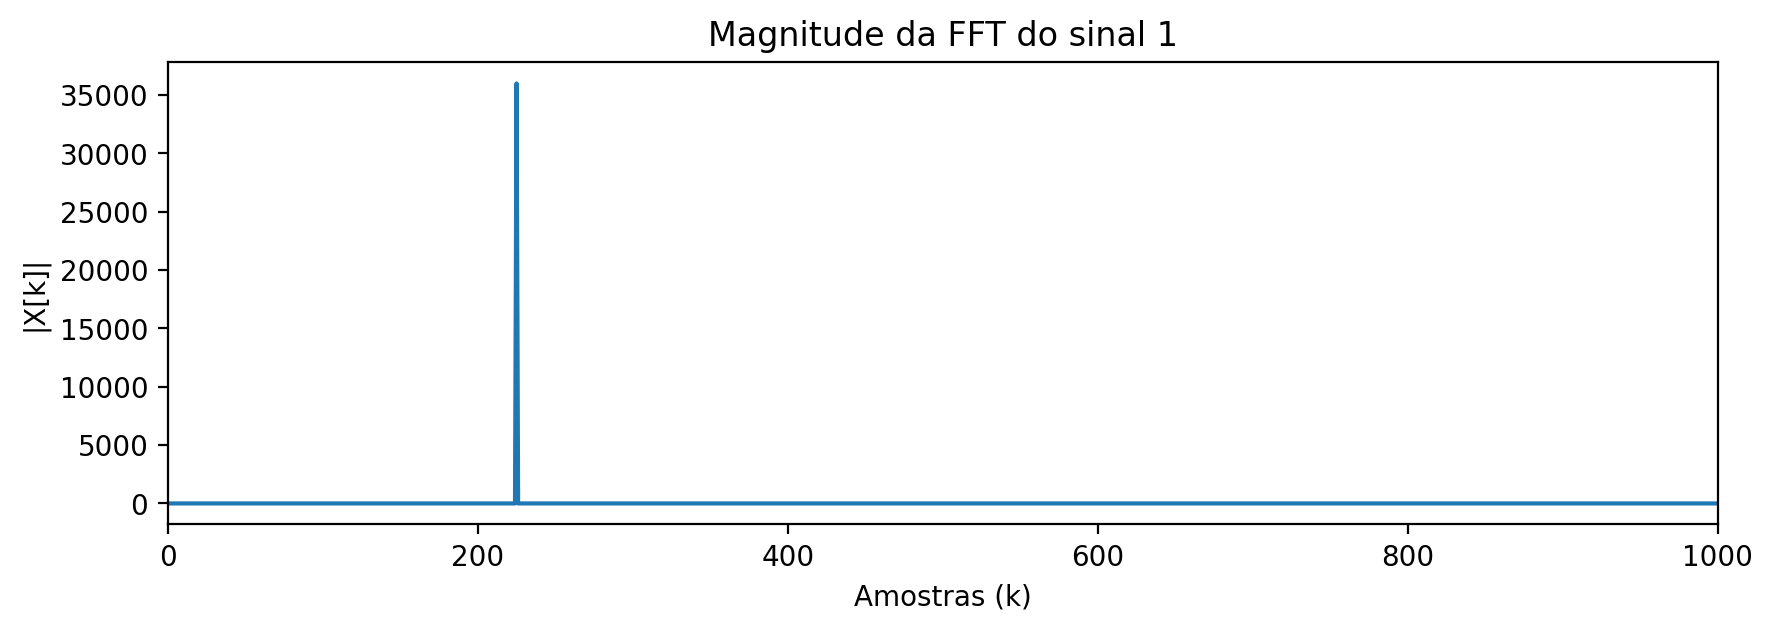

Pico em k = 225 -> frequência = 150.0 Hz


In [42]:
import numpy as np
import matplotlib.pyplot as plt

# Magnitude da FFT
Xmag = np.abs(np.fft.fft(x1))

# Eixo no domínio das amostras (índice k da FFT)
n = np.arange(len(Xmag))

# Plot (só a primeira metade, pois a outra é o espelho)
plt.figure(figsize=(10, 3))
plt.plot(n[:len(n)//2], Xmag[:len(n)//2])
plt.title('Magnitude da FFT do sinal 1')
plt.xlabel('Amostras (k)')
plt.ylabel('|X[k]|')
plt.xlim(0, 1000)   # aproxima do pico
plt.show()

# Conferência: frequência do pico em Hz
k_pico = np.argmax(Xmag[:len(Xmag)//2])
print('Pico em k =', k_pico, '-> frequência =', k_pico * fs1 / len(x1), 'Hz')

Aproveitando a ***simetria***, faça um recorte, apropriado, de apenas a metade das amostras.

<img src="./figures/spec_02.png" alt="" width="600"/>

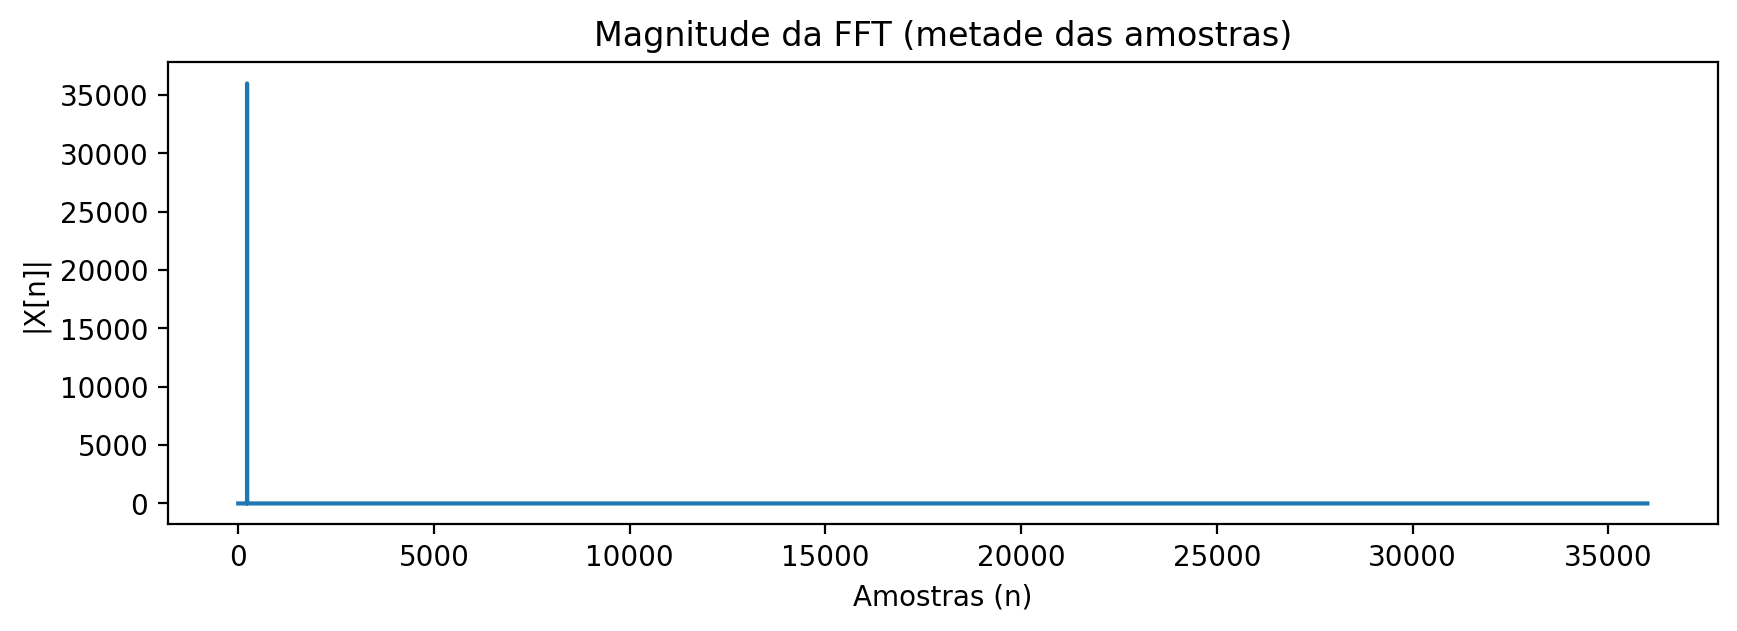

In [43]:
import numpy as np
import matplotlib.pyplot as plt

# Recorte no domínio das amostras: só a metade, por causa da simetria da FFT
r = len(Xmag) // 2

plt.figure(figsize=(10, 3))
plt.plot(n[:r], Xmag[:r])
plt.title('Magnitude da FFT (metade das amostras)')
plt.xlabel('Amostras (n)')
plt.ylabel('|X[n]|')
plt.show()

## Plotando as frequências

Agora vamos renomear o eixo horizontal para apresentar o sinal no "***domínio da frequência***":

$$
\Large
f = \frac{n}{N} f_{s}
$$

<img src="./figures/spec_03.png" alt="" width="600"/>

In [ ]:
# f = (n / N) * fs
N = len(x1)
fHz = n / N * fs1

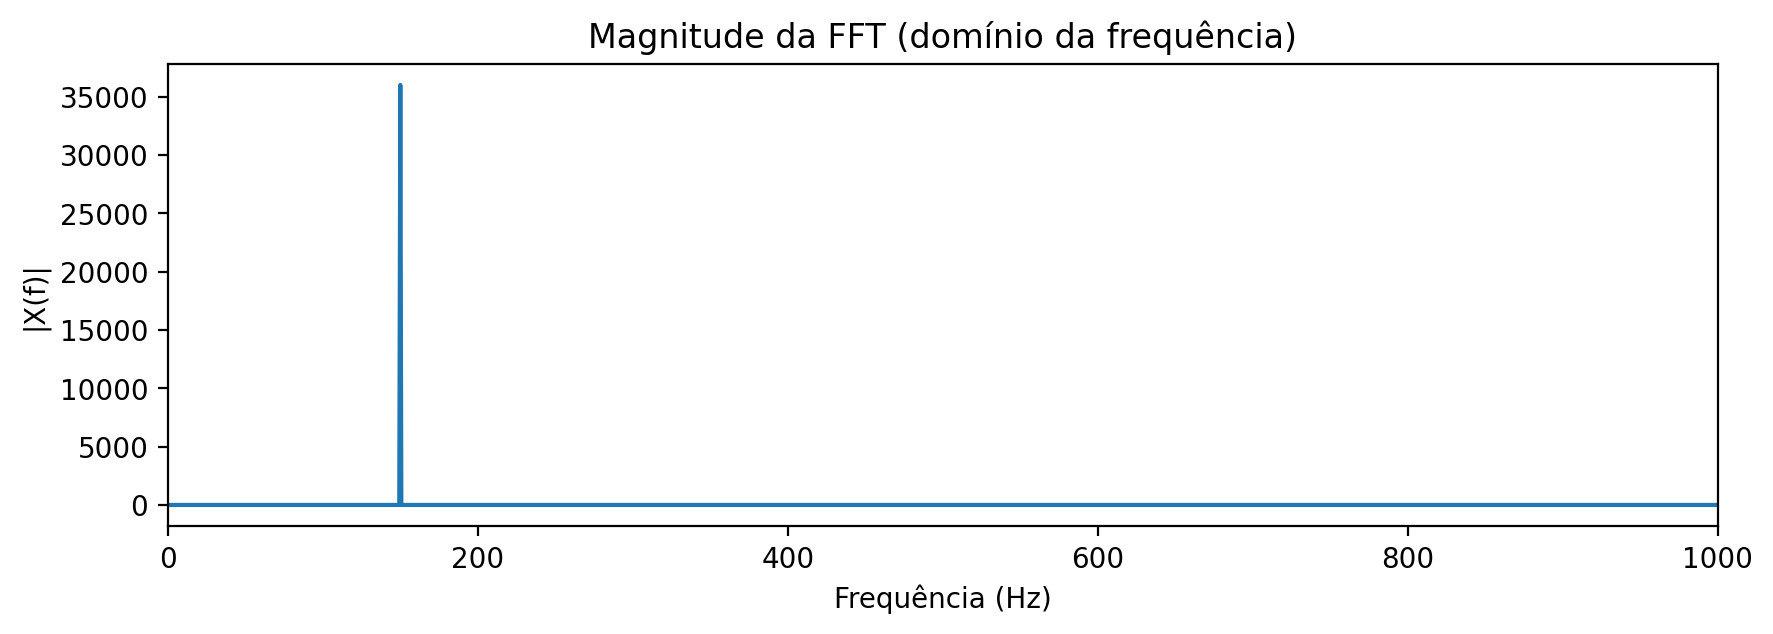

In [ ]:
plt.figure(figsize=(10, 3))
plt.plot(fHz[:r], Xmag[:r])
plt.title('Magnitude da FFT (domínio da frequência)')
plt.xlabel('Frequência (Hz)')
plt.ylabel('|X(f)|')
plt.xlim(0, 1000)   # aproxima do pico
plt.show()

Aproveite o recorte anterior **no domínio das amostras** e aplique-o no sinal.

<img src="./figures/spec_04.png" alt="" width="600"/>

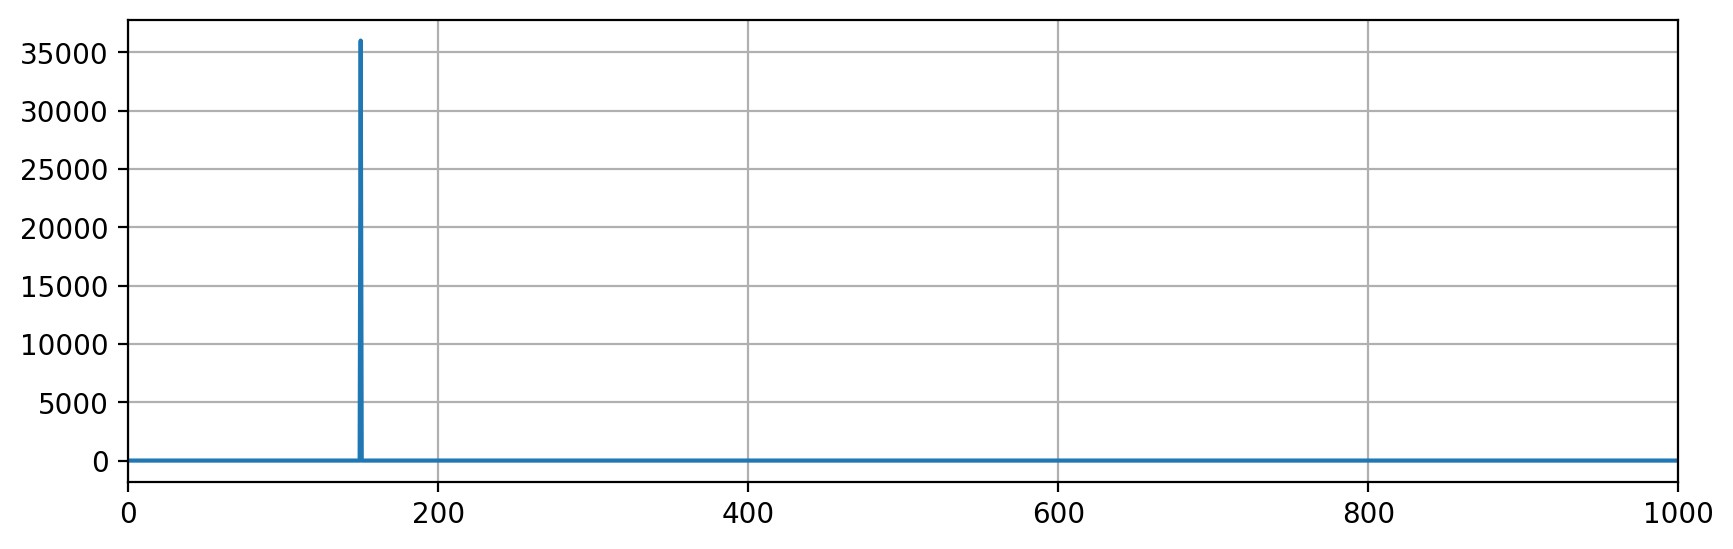

In [50]:
import numpy as np
import matplotlib.pyplot as plt

def SIGNALplot(x, t=None, xlim=None):
    '''
    x   : sinal (eixo vertical)
    t   : eixo horizontal (amostras, segundos ou Hz)
    xlim: [min, max] do eixo horizontal
    '''
    if t is None:
        t = np.arange(len(x))
    plt.figure(figsize=(10, 3))
    plt.plot(t, x)
    if xlim is not None:
        plt.xlim(xlim)
    plt.grid(True)
    plt.show()

# Recria o que as células anteriores faziam
Xmag = np.abs(np.fft.fft(x1))
n = np.arange(len(Xmag))
fHz = n / len(x1) * fs1

# Recorte: metade das amostras (simetria da FFT)
r = len(Xmag) // 2

SIGNALplot(Xmag[:r], fHz[:r], xlim=[0, 1000])

Agora, aplique um recorte similar **no domínio das frequências**.

<img src="./figures/spec_05.png" alt="" width="600"/>

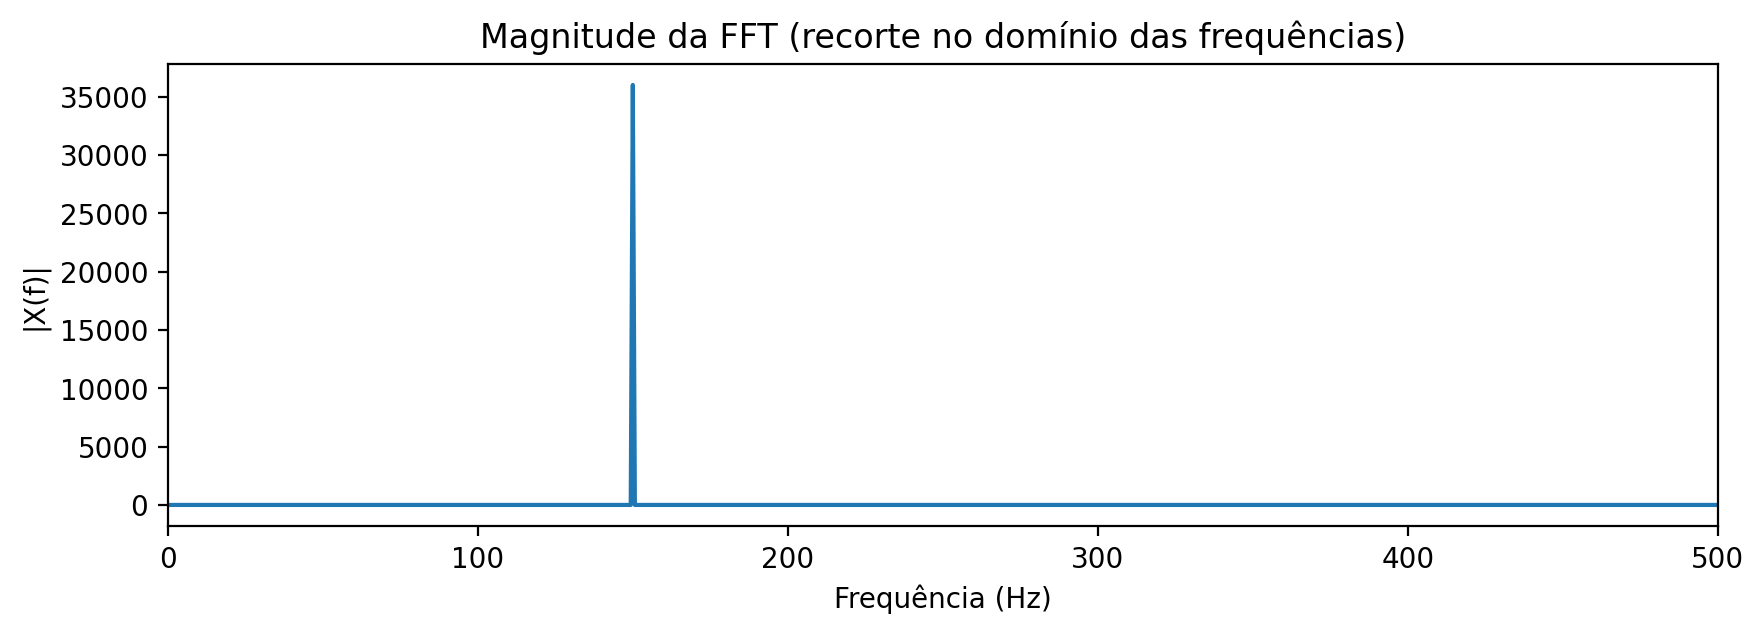

In [51]:
import matplotlib.pyplot as plt

# Recorte no domínio das frequências: mostra só de 0 a 500 Hz
plt.figure(figsize=(10, 3))
plt.plot(fHz, Xmag)
plt.xlim([0, 500])
plt.title('Magnitude da FFT (recorte no domínio das frequências)')
plt.xlabel('Frequência (Hz)')
plt.ylabel('|X(f)|')
plt.show()

Plote a ***forma de onda*** e o ***espectro*** para um único sinal com frequencias de 200, 400, 600 e 800 Hz e 1 segundo de duração.

<img src="./figures/sine_04.png" alt="" width="600"/>

<img src="./figures/spec_06.png" alt="" width="600"/>

In [52]:
# Resposta
import numpy as np
import matplotlib.pyplot as plt

# Soma de 4 tons (200, 400, 600 e 800 Hz), 1 segundo
x = 0
for f_i in [200, 400, 600, 800]:
    xi, fs_x = SIGNALtone(f_i, 1.0)
    x = x + xi

x = x / np.max(np.abs(x))   # normaliza para não saturar o áudio

# Vetor de tempo
tx = np.arange(len(x)) / fs_x

# Espectro (magnitude da FFT) e eixo em Hz
Xmag = np.abs(np.fft.fft(x))
fHz_x = np.arange(len(x)) / len(x) * fs_x

In [53]:
play(x, fs_x)

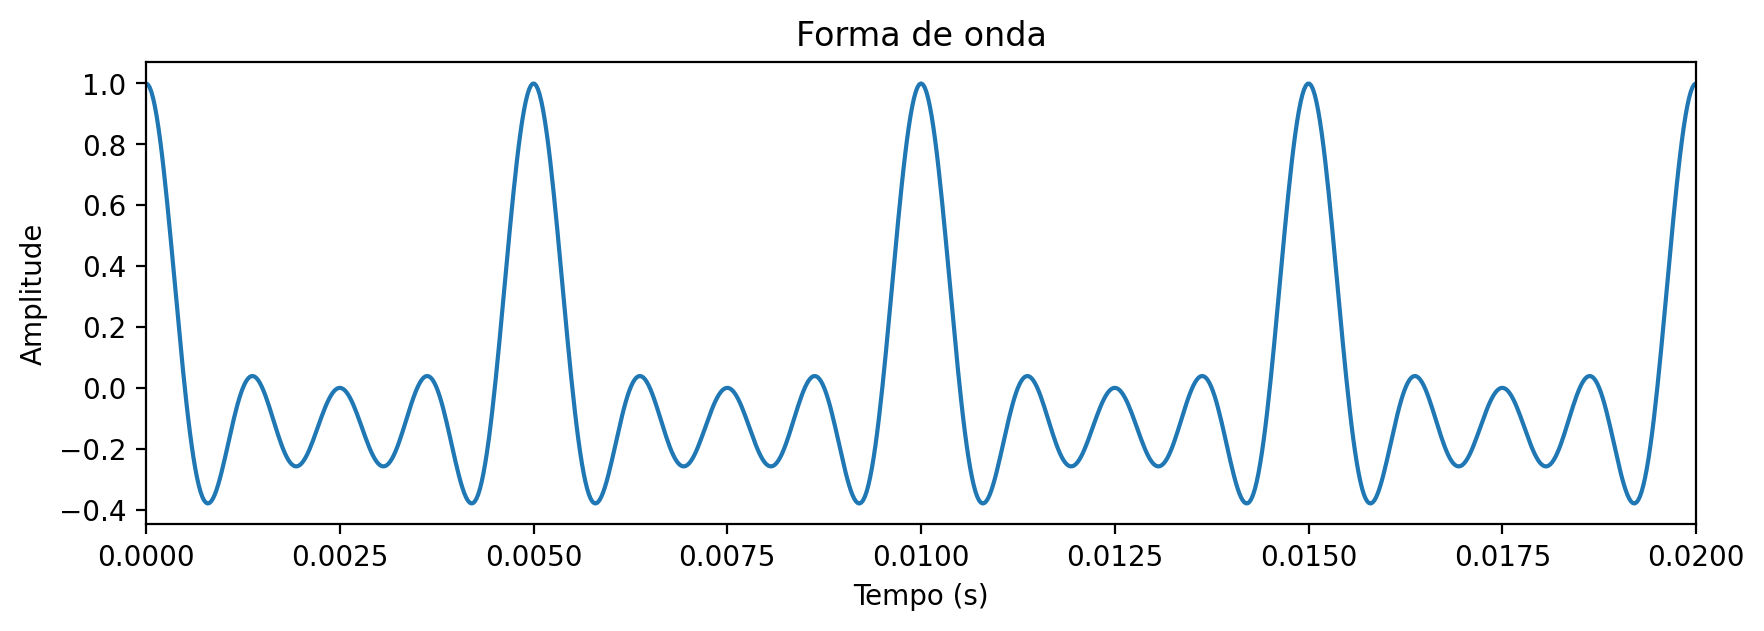

In [54]:
plt.figure(figsize=(10, 3))
plt.plot(tx, x)
plt.xlim([0, 0.02])   # primeiros 20 ms
plt.title('Forma de onda')
plt.xlabel('Tempo (s)')
plt.ylabel('Amplitude')
plt.show()

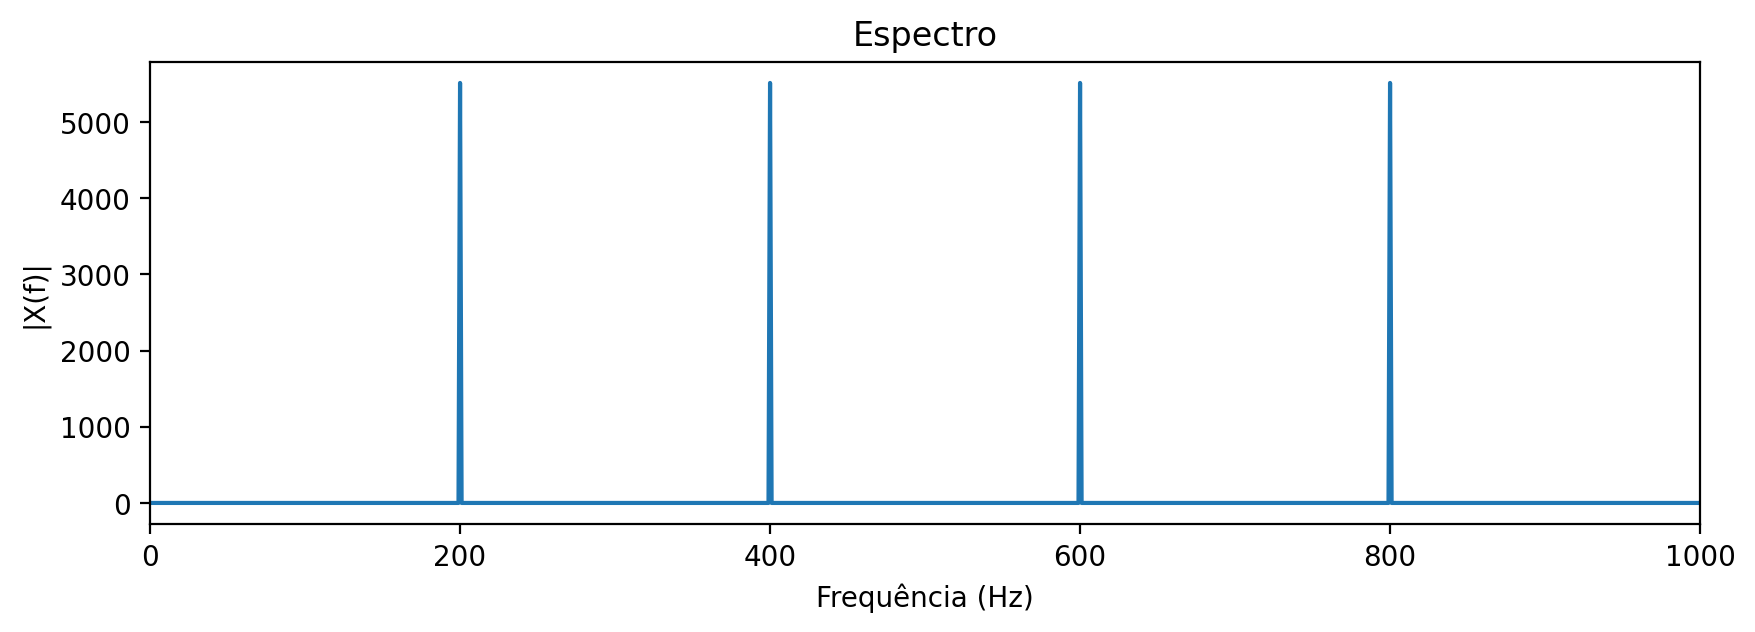

In [55]:
plt.figure(figsize=(10, 3))
plt.plot(fHz_x, Xmag)
plt.xlim([0, 1000])   # mostra os 4 picos
plt.title('Espectro')
plt.xlabel('Frequência (Hz)')
plt.ylabel('|X(f)|')
plt.show()

Oba! Agora sim conseguimos gerar e comprovar as frequencias, ou "*velocidades*", presentes nos sinais!

## Bonus track

A partir da primitiva `SIGNALgenerate`, aumente a sua **biblioteca de processamento sinais** com a função `SIGNALwaveform`, que admita ***tons*** com [***formas de onda*** (*waveforms*)](https://en.wikipedia.org/wiki/Waveform) aleatórias.

***Dica:*** Comece criando um sinal aleatório de tamanho igual a um período. Depois é apenas replicar o sinal até o tamanho final usando `np.concatenate`.

In [56]:
import numpy as np

def SIGNALwaveform(f=440.0, dur=1.0):
    '''
    Tone with a random waveform as input

    f  : Signal frequency
    dur: Duration (seconds)

    x  : Output signal
    fs : Sampling freq. (CD standard by def.)
    '''

    fs = 44.1e3  # Sampling freq. (CD standard)

    N = int(dur * fs)        # número total de amostras
    P = int(round(fs / f))   # período em amostras (inteiro)

    # Uma forma de onda aleatória com o tamanho de um período
    waveform = SIGNALgenerate(P, 'random')

    # Replica o período até o tamanho final
    reps = int(np.ceil(N / P))
    x = np.concatenate([waveform] * reps)[:N]

    return x, fs

Teste a função para um sinal de 110 Hz e 1 segundo de duração.

In [60]:
f = 200
dur = 1.0

y, fs = SIGNALwaveform(f, dur)

In [61]:
play(y, fs)

Verifique a frequencia do sinal gerado. \
O que achou de diferente nele?

<img src="./figures/spec_07.png" alt="" width="600"/>

In [ ]:
# A frequência continua sendo 110 Hz, mas agora aparecem harmônicos (múltiplos de 110 Hz) com amplitudes aleatórias, em vez de um único pico

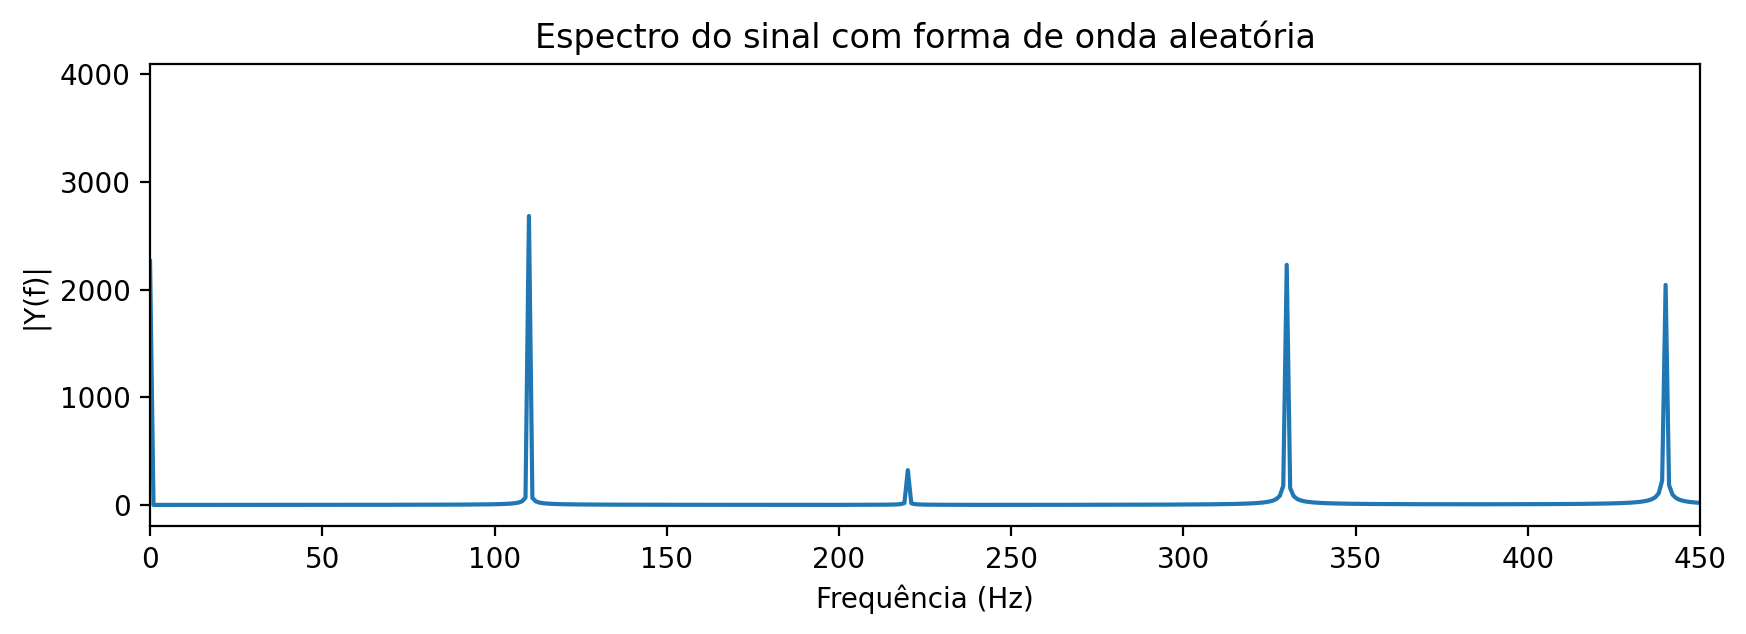

In [62]:
import numpy as np
import matplotlib.pyplot as plt

# Sinal com forma de onda aleatória (110 Hz, 1 s)
y, fs_y = SIGNALwaveform(110.0, 1.0)

# Espectro (magnitude da FFT) e eixo em Hz
Ymag = np.abs(np.fft.fft(y))
fHz_y = np.arange(len(y)) / len(y) * fs_y

plt.figure(figsize=(10, 3))
plt.plot(fHz_y, Ymag)
plt.xlim([0, 450])
plt.title('Espectro do sinal com forma de onda aleatória')
plt.xlabel('Frequência (Hz)')
plt.ylabel('|Y(f)|')
plt.show()

Plote apenas 5 períodos do sinal.

<img src="./figures/signal_01.png" alt="" width="600"/>

In [63]:
# Período em amostras (o mesmo arredondamento usado na SIGNALwaveform)
P = int(round(fs_y / 110.0))

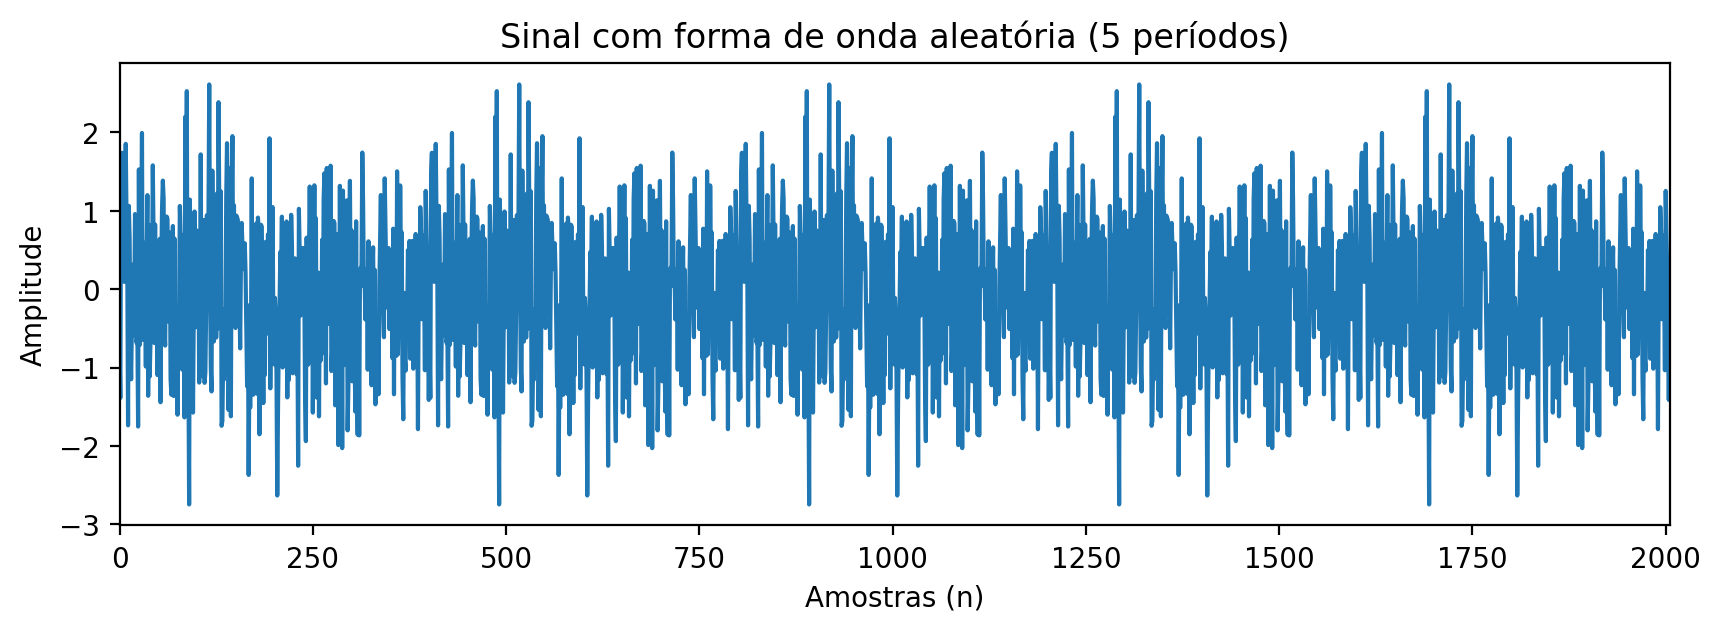

In [64]:
import numpy as np
import matplotlib.pyplot as plt

# Eixo em amostras
ny = np.arange(len(y))

plt.figure(figsize=(10, 3))
plt.plot(ny, y)
plt.xlim([0, 5 * P])   # apenas 5 períodos
plt.title('Sinal com forma de onda aleatória (5 períodos)')
plt.xlabel('Amostras (n)')
plt.ylabel('Amplitude')
plt.show()

Pronto! Agora estamos preparados para analisar sinais no ***domínio da frequência!***

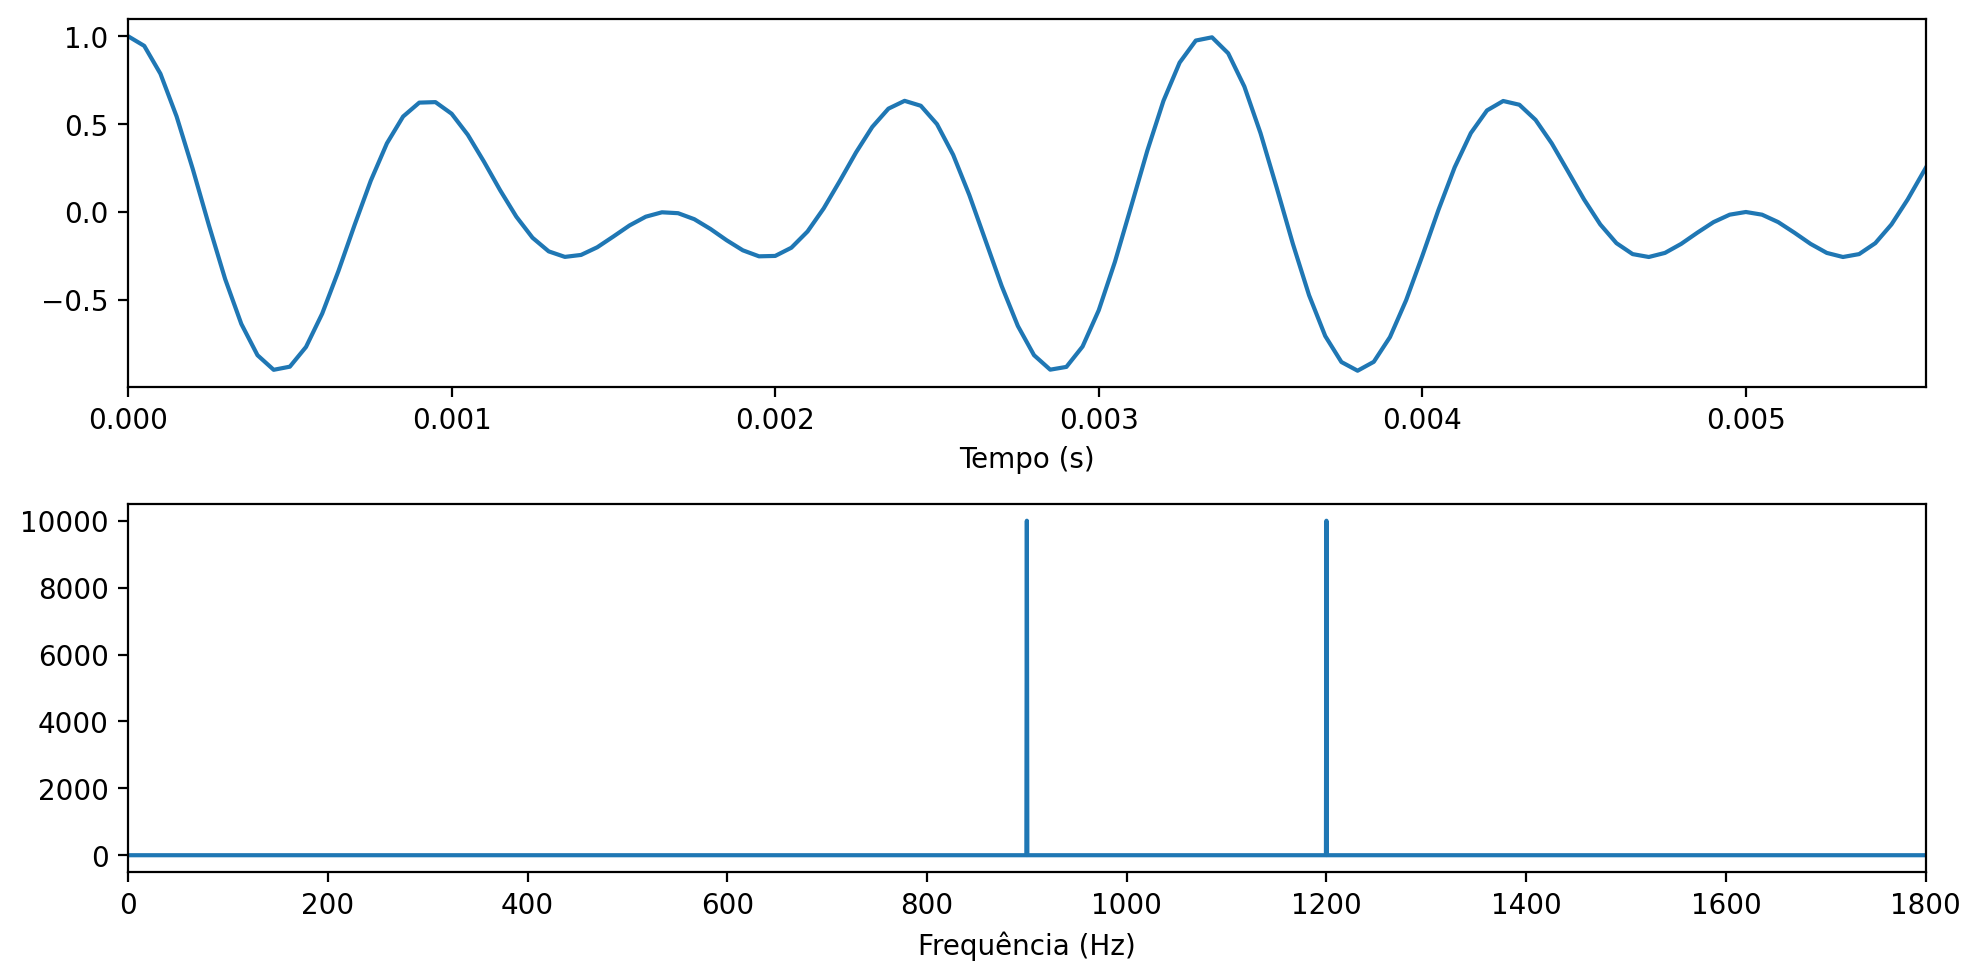

In [93]:
import numpy as np, matplotlib.pyplot as plt

f1, f2,dur, fs = 900, 1200, 2, 20000

x = (SIGNALgenerate(int(dur*fs), 'osc', {'P': fs/f1, 'A': 0.5}) +
     SIGNALgenerate(int(dur*fs), 'osc', {'P': fs/f2, 'A': 0.5}))
play(x, fs)

X, fHz = np.abs(np.fft.rfft(x)), np.fft.rfftfreq(len(x), 1/fs)
fig, ax = plt.subplots(2, 1, figsize=(10, 5))
ax[0].plot(np.arange(len(x))/fs, x); ax[0].set_xlim(0, 5/f); ax[0].set_xlabel('Tempo (s)')
ax[1].plot(fHz, X); ax[1].set_xlim(0, 2*f); ax[1].set_xlabel('Frequência (Hz)')
plt.tight_layout(); plt.show()